# Imports

In [3]:
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader
from torchvision import datasets, transforms
from torchvision.utils import make_grid
from torch.utils.data import random_split
import torchvision.transforms.functional as TF
from torch.utils.data import TensorDataset


import numpy as np
import pandas as pd
import random
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import time

# Treinando e testando NN e CNN usando o dataset MNIST

## Fixando as seeds

In [4]:
seed = 15

random.seed(seed)
np.random.seed(seed)
torch.manual_seed(seed)
torch.cuda.manual_seed(seed)
torch.cuda.manual_seed_all(seed)
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

## Carregando o dataset

In [5]:
transform_NN = transforms.ToTensor()

train_data = datasets.MNIST(root='/', train=True, download=True, transform=transform_NN)
test_data = datasets.MNIST(root='/', train=False, download=True, transform=transform_NN)

train_size = int(0.8 * len(train_data))
val_size = len(train_data) - train_size

train_data, validation_data = random_split(train_data, [train_size, val_size], generator=torch.Generator().manual_seed(seed))

# Batch size de 10
train_data = DataLoader(train_data, batch_size=10)
test_data = DataLoader(test_data, batch_size=10)
validation_data = DataLoader(validation_data, batch_size=10)


100%|██████████| 9.91M/9.91M [00:00<00:00, 24.3MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 601kB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 5.58MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 9.24MB/s]


## NN

### Definindo a Arquitetura da NN

In [ ]:
class NN(nn.Module):
  def __init__(self, num_features, num_classes):
    super().__init__()
    self.c1 = nn.Linear(num_features, 50)
    self.c2 = nn.Linear(50, 100)
    self.c3 = nn.Linear(100, 50)
    self.out = nn.Linear(50, num_classes)

  def forward(self, x):
    x = torch.flatten(x, 1)
    x = F.relu(self.c1(x))
    x = F.relu(self.c2(x))
    x = F.relu(self.c3(x))
    x = self.out(x)

    return x

### Treinando a NN

In [ ]:
model_nn = NN(28*28, 10)

criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.SGD(model_nn.parameters(), lr=0.01)

patience = 3
delta = 0.01
melhor_loss_validacao = float('inf')
epochs_sem_melhora = 0

epochs = 50
AcertosEmCadaEpoch_NN = []
LossMediaEmCadaEpoch_NN = []
AcertosEmCadaEpoch_Validacao_NN = []
LossMediaEmCadaEpoch_Validacao_NN = []
start_time_NN = time.time()

for i in range(epochs):
  AcertosNaEpoch = 0
  SomaLossNaEpoch = 0


  # treino
  # Passa pelos batches
  for b,(x_train, y_train) in enumerate(train_data):
    y_pred = model_nn(x_train)
    loss = criterion(y_pred, y_train)


    predicted = torch.argmax(y_pred, dim=1)
    acertosNoBatch = (predicted == y_train).sum()
    AcertosNaEpoch += acertosNoBatch
    SomaLossNaEpoch += loss.item()

    optimizer.zero_grad()
    loss.backward()
    optimizer.step()


    if b%600 == 0:
      print(f'Epoch: {i+1}  Batch: {b}  Loss: {loss.item()}')

  AcertosEmCadaEpoch_NN.append(AcertosNaEpoch)
  LossMediaEmCadaEpoch_NN.append(SomaLossNaEpoch/len(train_data))
  ###

  # Validacao
  AcertosNaValidacao = 0
  SomaLossNaValidacao = 0

  # Pra nao modificar o treino
  with torch.no_grad():

      # Passa pelos batches
      for x_validation, y_validation in validation_data:
          y_pred = model_nn(x_validation)
          loss = criterion(y_pred, y_validation)

          predicted = torch.argmax(y_pred, dim=1)

          acertosNoBatch = (predicted == y_validation).sum()
          AcertosNaValidacao += acertosNoBatch
          SomaLossNaValidacao += loss.item()

  LossValidacaoAtual = SomaLossNaValidacao / len(validation_data)
  AcertosEmCadaEpoch_Validacao_NN.append(AcertosNaValidacao)
  LossMediaEmCadaEpoch_Validacao_NN.append(LossValidacaoAtual)

  if melhor_loss_validacao - LossValidacaoAtual > delta:
    melhor_loss_validacao = LossValidacaoAtual
    epochs_sem_melhora = 0
  else:
    epochs_sem_melhora += 1

  if epochs_sem_melhora >= patience:
    print(f'Early Stopping na epoch {i+1}')
    break

######  Fim do laco das epocas

current_time_NN = time.time()
total_time_NN = current_time_NN - start_time_NN
epocas_NN = len(AcertosEmCadaEpoch_NN)

# Teste
AcertosNoTest = 0
SomaLossNoTeste = 0
with torch.no_grad():
  for b,(x_test, y_test) in enumerate(test_data):
    y_pred = model_nn(x_test)
    predicted = torch.argmax(y_pred, dim=1)
    loss = criterion(y_pred, y_test)
    SomaLossNoTeste += loss.item()
    AcertosNoBacth = (predicted == y_test).sum()
    AcertosNoTest += AcertosNoBacth

LossMediaNoTeste = SomaLossNoTeste/len(test_data)

Epoch: 1  Batch: 0  Loss: 2.270596981048584
Epoch: 1  Batch: 600  Loss: 2.2340455055236816
Epoch: 1  Batch: 1200  Loss: 1.6609752178192139
Epoch: 1  Batch: 1800  Loss: 0.5381722450256348
Epoch: 1  Batch: 2400  Loss: 1.1377947330474854
Epoch: 1  Batch: 3000  Loss: 0.6637373566627502
Epoch: 1  Batch: 3600  Loss: 0.3874022960662842
Epoch: 1  Batch: 4200  Loss: 0.3570132851600647
Epoch: 2  Batch: 0  Loss: 0.18674758076667786
Epoch: 2  Batch: 600  Loss: 0.19706514477729797
Epoch: 2  Batch: 1200  Loss: 0.10760289430618286
Epoch: 2  Batch: 1800  Loss: 0.3076401948928833
Epoch: 2  Batch: 2400  Loss: 0.9078198671340942
Epoch: 2  Batch: 3000  Loss: 0.2647601068019867
Epoch: 2  Batch: 3600  Loss: 0.15063126385211945
Epoch: 2  Batch: 4200  Loss: 0.2284834384918213
Epoch: 3  Batch: 0  Loss: 0.0854906290769577
Epoch: 3  Batch: 600  Loss: 0.1141425371170044
Epoch: 3  Batch: 1200  Loss: 0.04718756675720215
Epoch: 3  Batch: 1800  Loss: 0.34099793434143066
Epoch: 3  Batch: 2400  Loss: 0.6173785924911499

In [ ]:
print(f'Loss media no teste: {LossMediaNoTeste}')
print(f'Acertos no test: {AcertosNoTest}')
AcuraciaNoTeste = (AcertosNoTest.item() / len(test_data.dataset)) * 100
print(f'Acurácia no teste: {AcuraciaNoTeste:.2f}%')
print(f'Tempo ate a convergencia: {total_time_NN} segundos')
print(f'Numero de epocas ate a convergencia: {epocas_NN}')

Loss media no teste: 0.12557315975695382
Acertos no test: 9628
Acurácia no teste: 96.28%
Tempo ate a convergencia: 111.10887169837952 segundos
Numero de epocas ate a convergencia: 11


### Visualizando resultados

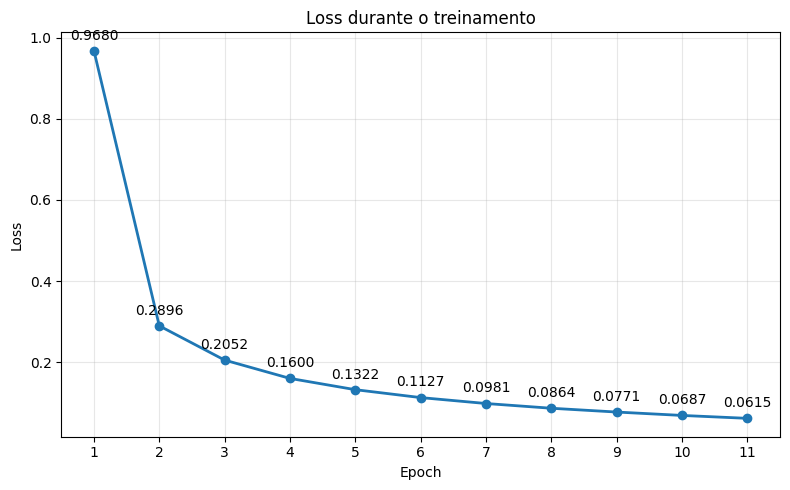

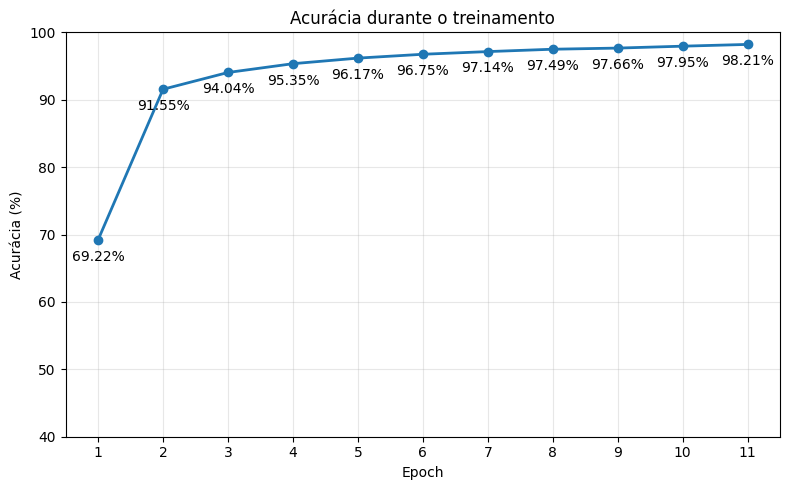

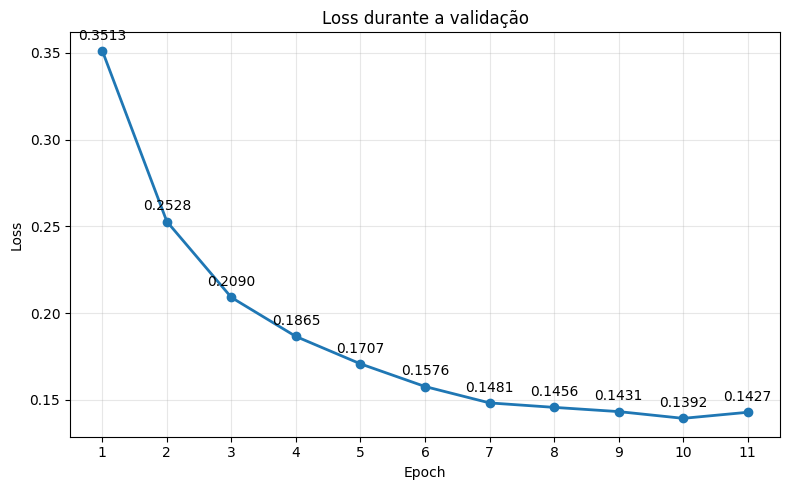

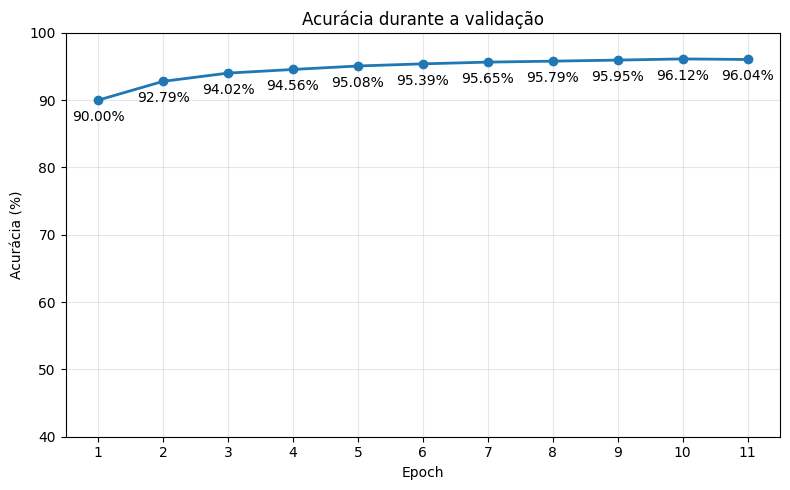

Acurácia no teste: 96.28%


In [ ]:
total_amostras_treino = len(train_data.dataset)
total_amostras_validacao = len(validation_data.dataset)

AcuraciaEmCadaEpoch_NN = []
AcuraciaValidacaoEmCadaEpoch_NN = []

for acertos in AcertosEmCadaEpoch_NN:
    acuracia = (acertos.item() / total_amostras_treino) * 100
    AcuraciaEmCadaEpoch_NN.append(acuracia)

for acertos in AcertosEmCadaEpoch_Validacao_NN:
    acuracia = (acertos.item() / total_amostras_validacao) * 100
    AcuraciaValidacaoEmCadaEpoch_NN.append(acuracia)

epochs_lista = range(1, epocas_NN + 1)


## Treino
plt.figure(figsize=(8, 5))

plt.plot(epochs_lista, LossMediaEmCadaEpoch_NN, marker='o', linewidth=2)

for i in range(len(LossMediaEmCadaEpoch_NN)):
    plt.annotate(f'{LossMediaEmCadaEpoch_NN[i]:.4f}', (epochs_lista[i], LossMediaEmCadaEpoch_NN[i]), xytext=(0, 8), textcoords='offset points', ha='center')

plt.title('Loss durante o treinamento')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.xticks(epochs_lista)
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


plt.figure(figsize=(8, 5))

plt.plot(epochs_lista, AcuraciaEmCadaEpoch_NN, marker='o', linewidth=2)

for i in range(len(AcuraciaEmCadaEpoch_NN)):
    plt.annotate(f'{AcuraciaEmCadaEpoch_NN[i]:.2f}%', (epochs_lista[i], AcuraciaEmCadaEpoch_NN[i]), xytext=(0, -15), textcoords='offset points', ha='center')

plt.title('Acurácia durante o treinamento')
plt.xlabel('Epoch')
plt.ylabel('Acurácia (%)')
plt.xticks(epochs_lista)
plt.ylim(40, 100)
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

##

## Validacao

plt.figure(figsize=(8, 5))

plt.plot(epochs_lista, LossMediaEmCadaEpoch_Validacao_NN, marker='o', linewidth=2)

for i in range(len(LossMediaEmCadaEpoch_Validacao_NN)):
    plt.annotate(f'{LossMediaEmCadaEpoch_Validacao_NN[i]:.4f}', (epochs_lista[i], LossMediaEmCadaEpoch_Validacao_NN[i]), xytext=(0, 8), textcoords='offset points', ha='center')

plt.title('Loss durante a validação')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.xticks(epochs_lista)
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


plt.figure(figsize=(8, 5))

plt.plot(epochs_lista, AcuraciaValidacaoEmCadaEpoch_NN, marker='o', linewidth=2)

for i in range(len(AcuraciaValidacaoEmCadaEpoch_NN)):
    plt.annotate(f'{AcuraciaValidacaoEmCadaEpoch_NN[i]:.2f}%', (epochs_lista[i], AcuraciaValidacaoEmCadaEpoch_NN[i]), xytext=(0, -15), textcoords='offset points', ha='center')

plt.title('Acurácia durante a validação')
plt.xlabel('Epoch')
plt.ylabel('Acurácia (%)')
plt.xticks(epochs_lista)
plt.ylim(40, 100)
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

##


AcuraciaNoTeste = (AcertosNoTest.item() / len(test_data.dataset)) * 100

print(f'Acurácia no teste: {AcuraciaNoTeste:.2f}%')

## CNN


### Definindo a Arquitetura da CNN

In [ ]:
class CNN(nn.Module):
    def __init__(self,num_classes, in_channel, size):
        super().__init__()

        self.conv1 = nn.Conv2d(in_channel, 36, 3, 1)
        self.conv2 = nn.Conv2d(36, 42, 3, 1)
        self.conv3 = nn.Conv2d(42, 60, 3, 1)


        # Para descobrir automaticamente o tamanho da entrada da cabeca de classificacao
        with torch.no_grad():
            x = torch.zeros(1, in_channel, size, size)
            x = F.relu(self.conv1(x))
            x = F.max_pool2d(x, 2, 2)
            x = F.relu(self.conv2(x))
            x = F.max_pool2d(x, 2, 2)
            x = F.relu(self.conv3(x))
            x = F.max_pool2d(x, 2, 2)

            flattened_size = x.flatten(1).shape[1]

        self.c1 = nn.Linear(flattened_size, 120)
        self.c2 = nn.Linear(120, 80)
        self.c3 = nn.Linear(80, num_classes)

    def forward(self, X):
        X = F.relu(self.conv1(X))
        X = F.max_pool2d(X, 2, 2)

        X = F.relu(self.conv2(X))
        X = F.max_pool2d(X, 2, 2)
        X = F.relu(self.conv3(X))
        X = F.max_pool2d(X, 2, 2)

        X = torch.flatten(X, 1)

        X = F.relu(self.c1(X))
        X = F.relu(self.c2(X))
        X = self.c3(X)

        return X

### Treinando a CNN

In [ ]:
model_cnn = CNN(10,1,28)

criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.SGD(model_cnn.parameters(), lr=0.01)

patience = 3
delta = 0.01
melhor_loss_validacao = float('inf')
epochs_sem_melhora = 0

epochs = 50
AcertosEmCadaEpoch_CNN = []
LossMediaEmCadaEpoch_CNN = []
AcertosEmCadaEpoch_Validacao_CNN = []
LossMediaEmCadaEpoch_Validacao_CNN = []
start_time_CNN = time.time()

for i in range(epochs):
  AcertosNaEpoch = 0
  SomaLossNaEpoch = 0


  # Train
  for b,(x_train, y_train) in enumerate(train_data):
    y_pred = model_cnn(x_train)
    loss = criterion(y_pred, y_train)

    predicted = torch.argmax(y_pred, dim=1)
    acertosNoBatch = (predicted == y_train).sum()
    AcertosNaEpoch += acertosNoBatch
    SomaLossNaEpoch += loss.item()

    optimizer.zero_grad()
    loss.backward()
    optimizer.step()


    if b%600 == 0:
      print(f'Epoch: {i+1}  Batch: {b}  Loss: {loss.item()}')

  AcertosEmCadaEpoch_CNN.append(AcertosNaEpoch)
  LossMediaEmCadaEpoch_CNN.append(SomaLossNaEpoch/len(train_data))


  # Validation
  AcertosNaValidacao = 0
  SomaLossNaValidacao = 0

  with torch.no_grad():
      for x_validation, y_validation in validation_data:
          y_pred = model_cnn(x_validation)
          loss = criterion(y_pred, y_validation)

          predicted = torch.argmax(y_pred, dim=1)

          acertosNoBatch = (predicted == y_validation).sum()
          AcertosNaValidacao += acertosNoBatch
          SomaLossNaValidacao += loss.item()

  LossValidacaoAtual = SomaLossNaValidacao / len(validation_data)
  AcertosEmCadaEpoch_Validacao_CNN.append(AcertosNaValidacao)
  LossMediaEmCadaEpoch_Validacao_CNN.append(LossValidacaoAtual)

  if melhor_loss_validacao - LossValidacaoAtual > delta:
    melhor_loss_validacao = LossValidacaoAtual
    epochs_sem_melhora = 0
  else:
    epochs_sem_melhora += 1

  if epochs_sem_melhora >= patience:
    print(f'Early Stopping na epoch {i+1}')
    break


current_time_CNN = time.time()
total_time_CNN = current_time_CNN - start_time_CNN
epocas_CNN = len(AcertosEmCadaEpoch_CNN)

# Test
AcertosNoTest = 0
SomaLossNoTeste = 0
with torch.no_grad():
  for b,(x_test, y_test) in enumerate(test_data):
    y_pred = model_cnn(x_test)
    predicted = torch.argmax(y_pred, dim=1)
    loss = criterion(y_pred, y_test)
    SomaLossNoTeste += loss.item()
    AcertosNoBacth = (predicted == y_test).sum()
    AcertosNoTest += AcertosNoBacth

LossMediaNoTeste = SomaLossNoTeste/len(test_data)

Epoch: 1  Batch: 0  Loss: 2.3252198696136475
Epoch: 1  Batch: 600  Loss: 2.279700517654419
Epoch: 1  Batch: 1200  Loss: 2.2977516651153564
Epoch: 1  Batch: 1800  Loss: 2.26941180229187
Epoch: 1  Batch: 2400  Loss: 2.2312028408050537
Epoch: 1  Batch: 3000  Loss: 1.7662874460220337
Epoch: 1  Batch: 3600  Loss: 0.7670284509658813
Epoch: 1  Batch: 4200  Loss: 0.3060820698738098
Epoch: 2  Batch: 0  Loss: 0.17920605838298798
Epoch: 2  Batch: 600  Loss: 0.06850171089172363
Epoch: 2  Batch: 1200  Loss: 0.13749226927757263
Epoch: 2  Batch: 1800  Loss: 0.15741972625255585
Epoch: 2  Batch: 2400  Loss: 0.704429030418396
Epoch: 2  Batch: 3000  Loss: 0.3492584526538849
Epoch: 2  Batch: 3600  Loss: 0.1167917475104332
Epoch: 2  Batch: 4200  Loss: 0.009523313492536545
Epoch: 3  Batch: 0  Loss: 0.055368948727846146
Epoch: 3  Batch: 600  Loss: 0.0484781377017498
Epoch: 3  Batch: 1200  Loss: 0.062497854232788086
Epoch: 3  Batch: 1800  Loss: 0.06923169642686844
Epoch: 3  Batch: 2400  Loss: 0.54703640937805

In [ ]:
print(f'Loss media no teste: {LossMediaNoTeste}')
print(f'Acertos no test: {AcertosNoTest}')
AcuraciaNoTeste = (AcertosNoTest.item() / len(test_data.dataset)) * 100
print(f'Acurácia no teste: {AcuraciaNoTeste:.2f}%')
print(f'Tempo ate a convergencia: {total_time_CNN} segundos')
print(f'Numero de epocas ate a convergencia: {epocas_CNN}')

Loss media no teste: 0.07213126064325479
Acertos no test: 9758
Acurácia no teste: 97.58%
Tempo ate a convergencia: 431.01810693740845 segundos
Numero de epocas ate a convergencia: 9


### Visualizando os resultados:

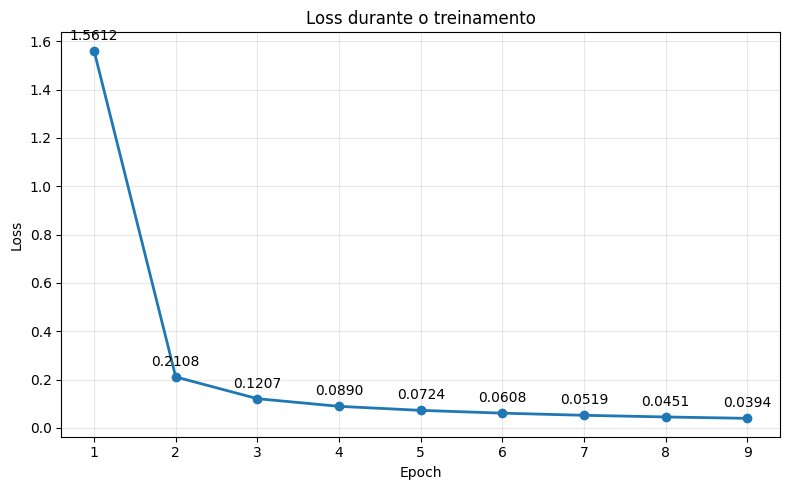

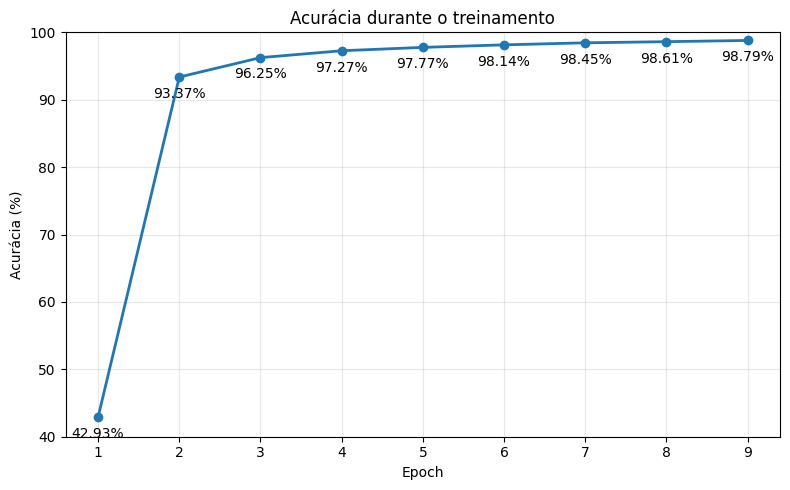

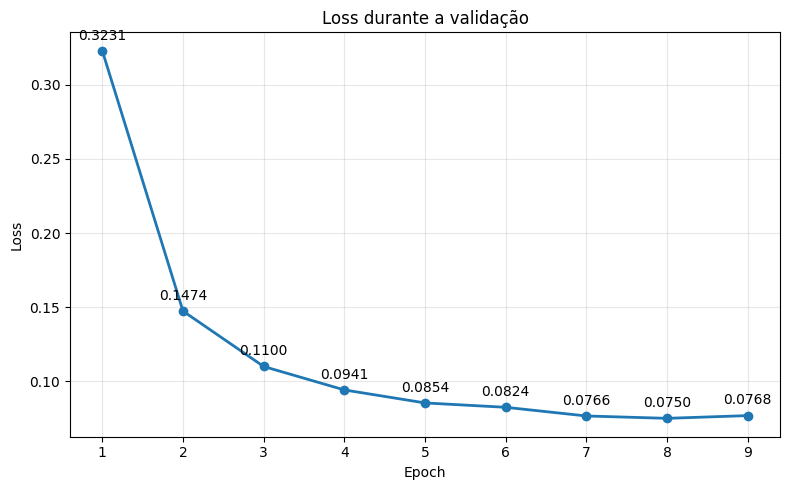

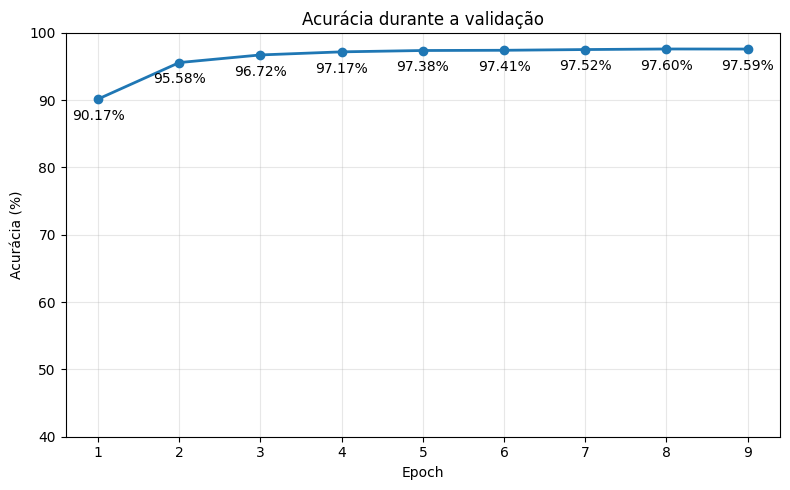

In [ ]:
total_amostras_treino = len(train_data.dataset)
total_amostras_validacao = len(validation_data.dataset)

AcuraciaEmCadaEpoch_CNN = []
AcuraciaValidacaoEmCadaEpoch_CNN = []

for acertos in AcertosEmCadaEpoch_CNN:
    acuracia = (acertos.item() / total_amostras_treino) * 100
    AcuraciaEmCadaEpoch_CNN.append(acuracia)

for acertos in AcertosEmCadaEpoch_Validacao_CNN:
    acuracia = (acertos.item() / total_amostras_validacao) * 100
    AcuraciaValidacaoEmCadaEpoch_CNN.append(acuracia)

epochs_lista = range(1, epocas_CNN + 1)

plt.figure(figsize=(8, 5))

plt.plot(epochs_lista, LossMediaEmCadaEpoch_CNN, marker='o', linewidth=2)

for i in range(len(LossMediaEmCadaEpoch_CNN)):
    plt.annotate(f'{LossMediaEmCadaEpoch_CNN[i]:.4f}', (epochs_lista[i], LossMediaEmCadaEpoch_CNN[i]), xytext=(0, 8), textcoords='offset points', ha='center')

plt.title('Loss durante o treinamento')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.xticks(epochs_lista)
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


plt.figure(figsize=(8, 5))

plt.plot(epochs_lista, AcuraciaEmCadaEpoch_CNN, marker='o', linewidth=2)

for i in range(len(AcuraciaEmCadaEpoch_CNN)):
    plt.annotate(f'{AcuraciaEmCadaEpoch_CNN[i]:.2f}%', (epochs_lista[i], AcuraciaEmCadaEpoch_CNN[i]), xytext=(0, -15), textcoords='offset points', ha='center')

plt.title('Acurácia durante o treinamento')
plt.xlabel('Epoch')
plt.ylabel('Acurácia (%)')
plt.xticks(epochs_lista)
plt.ylim(40, 100)
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()



## Validacao

plt.figure(figsize=(8, 5))

plt.plot(epochs_lista, LossMediaEmCadaEpoch_Validacao_CNN, marker='o', linewidth=2)

for i in range(len(LossMediaEmCadaEpoch_Validacao_CNN)):
    plt.annotate(f'{LossMediaEmCadaEpoch_Validacao_CNN[i]:.4f}', (epochs_lista[i], LossMediaEmCadaEpoch_Validacao_CNN[i]), xytext=(0, 8), textcoords='offset points', ha='center')

plt.title('Loss durante a validação')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.xticks(epochs_lista)
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


plt.figure(figsize=(8, 5))

plt.plot(epochs_lista, AcuraciaValidacaoEmCadaEpoch_CNN, marker='o', linewidth=2)

for i in range(len(AcuraciaValidacaoEmCadaEpoch_CNN)):
    plt.annotate(f'{AcuraciaValidacaoEmCadaEpoch_CNN[i]:.2f}%', (epochs_lista[i], AcuraciaValidacaoEmCadaEpoch_CNN[i]), xytext=(0, -15), textcoords='offset points', ha='center')

plt.title('Acurácia durante a validação')
plt.xlabel('Epoch')
plt.ylabel('Acurácia (%)')
plt.xticks(epochs_lista)
plt.ylim(40, 100)
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

##



## Comparando número de parâmetros:

In [ ]:
num_param_NN = 0

for p in model_nn.parameters():
    num_param_NN += p.numel()

num_param_CNN = 0

for p in model_cnn.parameters():
    num_param_CNN += p.numel()

print(f'Numero de parametros da NN: {num_param_NN}')
print(f'Numero de parametros da CNN: {num_param_CNN}')

Numero de parametros da NN: 49910
Numero de parametros da CNN: 54560


# Experimentos com MNSIT:


## Deslocar o posicionamento dos dígitos:

### Mostrando o deslocamento:

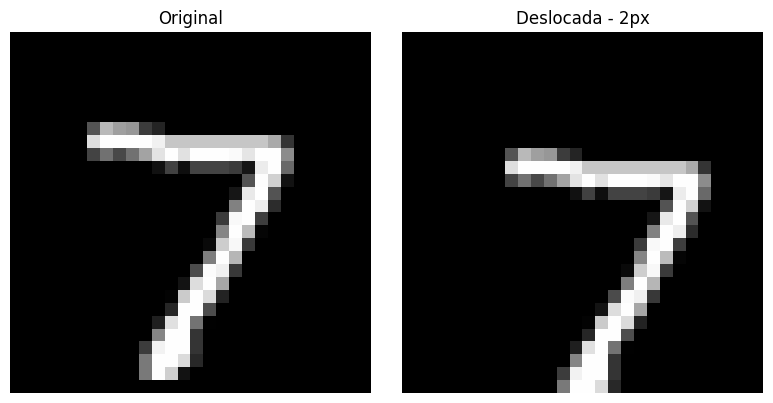

In [6]:
dx = 2
dy = 2

imagem_original, label = test_data.dataset[0]

imagem_deslocada = TF.affine(imagem_original, angle=0, translate=[dx, dy], scale=1, shear=[0, 0])

plt.figure(figsize=(8, 4))

plt.subplot(1, 2, 1)
plt.imshow(imagem_original.squeeze(), cmap='gray')
plt.title(f'Original')
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(imagem_deslocada.squeeze(), cmap='gray')
plt.title(f'Deslocada - {dx}px')
plt.axis('off')

plt.tight_layout()
plt.show()


### Testando os modelos no conjunto de teste com os dígitos deslocados:

Deslocamento: dx = 0.0, dy = 0.0
Acurácia NN: 96.28%
Acurácia CNN: 97.58%

Deslocamento: dx = 0.5, dy = 0.5
Acurácia NN: 88.26%
Acurácia CNN: 96.24%

Deslocamento: dx = 1.0, dy = 1.0
Acurácia NN: 82.20%
Acurácia CNN: 95.73%

Deslocamento: dx = 1.5, dy = 1.5
Acurácia NN: 53.15%
Acurácia CNN: 81.93%

Deslocamento: dx = 2.0, dy = 2.0
Acurácia NN: 44.26%
Acurácia CNN: 76.56%

Deslocamento: dx = 2.5, dy = 2.5
Acurácia NN: 25.23%
Acurácia CNN: 56.12%

Deslocamento: dx = 3.0, dy = 3.0
Acurácia NN: 17.76%
Acurácia CNN: 43.43%

Deslocamento: dx = 3.5, dy = 3.5
Acurácia NN: 7.82%
Acurácia CNN: 30.60%

Deslocamento: dx = 4.0, dy = 4.0
Acurácia NN: 5.67%
Acurácia CNN: 20.92%

Deslocamento: dx = 4.5, dy = 4.5
Acurácia NN: 4.82%
Acurácia CNN: 13.67%



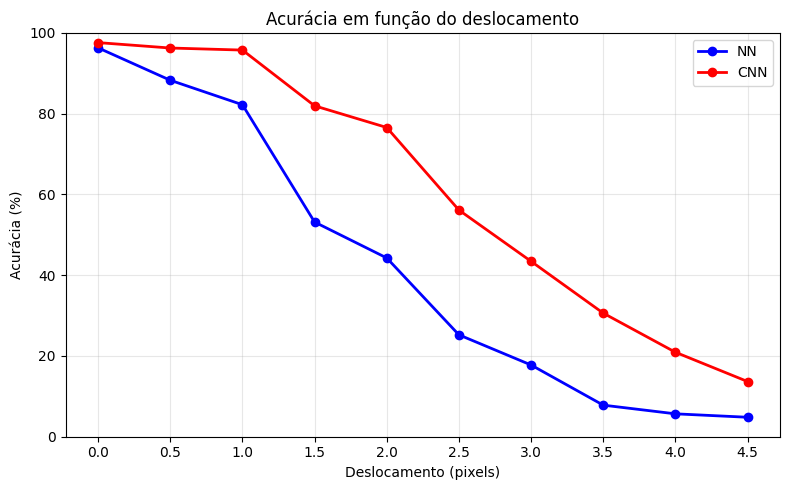

In [ ]:
acuracias_NN = []
acuracias_CNN = []
deslocamentos = []

dx = 0
dy = 0

for i in range(10):

    imagens_deslocadas = []
    labels_deslocados = []

    for imagem, label in test_data.dataset:
        imagem_deslocada = TF.affine(imagem, angle=0, translate=[dx, dy], scale=1, shear=[0, 0])
        imagens_deslocadas.append(imagem_deslocada)
        labels_deslocados.append(label)

    imagens_deslocadas = torch.stack(imagens_deslocadas)
    labels_deslocados = torch.tensor(labels_deslocados)

    test_data_deslocado = TensorDataset(imagens_deslocadas, labels_deslocados)
    test_data_deslocado = DataLoader(test_data_deslocado, batch_size=10)


    # Testando a NN
    AcertosNoTesteDeslocado_NN = 0

    with torch.no_grad():
        for x_test, y_test in test_data_deslocado:
            y_pred = model_nn(x_test)
            predicted = torch.argmax(y_pred, dim=1)
            AcertosNoTesteDeslocado_NN += (predicted == y_test).sum()

    AcuraciaNoTesteDeslocado_NN = (AcertosNoTesteDeslocado_NN.item() / len(test_data_deslocado.dataset)) * 100


    # Testando a CNN
    AcertosNoTesteDeslocado_CNN = 0

    with torch.no_grad():
        for x_test, y_test in test_data_deslocado:
            y_pred = model_cnn(x_test)
            predicted = torch.argmax(y_pred, dim=1)
            AcertosNoTesteDeslocado_CNN += (predicted == y_test).sum()

    AcuraciaNoTesteDeslocado_CNN = (AcertosNoTesteDeslocado_CNN.item() / len(test_data_deslocado.dataset)) * 100


    acuracias_NN.append(AcuraciaNoTesteDeslocado_NN)
    acuracias_CNN.append(AcuraciaNoTesteDeslocado_CNN)
    deslocamentos.append(dx)

    print(f'Deslocamento: dx = {dx:.1f}, dy = {dy:.1f}')
    print(f'Acurácia NN: {AcuraciaNoTesteDeslocado_NN:.2f}%')
    print(f'Acurácia CNN: {AcuraciaNoTesteDeslocado_CNN:.2f}%')
    print()

    dx += 0.5
    dy += 0.5


# Plotando os resultados
plt.figure(figsize=(8, 5))

plt.plot(deslocamentos, acuracias_NN, marker='o', linewidth=2, color='blue', label='NN')
plt.plot(deslocamentos, acuracias_CNN, marker='o', linewidth=2, color='red', label='CNN')

plt.title('Acurácia em função do deslocamento')
plt.xlabel('Deslocamento (pixels)')
plt.ylabel('Acurácia (%)')
plt.xticks(deslocamentos)
plt.ylim(0, 100)
plt.grid(True, alpha=0.3)
plt.legend()

plt.tight_layout()
plt.show()

## Rotacionar os dígitos:

### Mostrando a rotação:

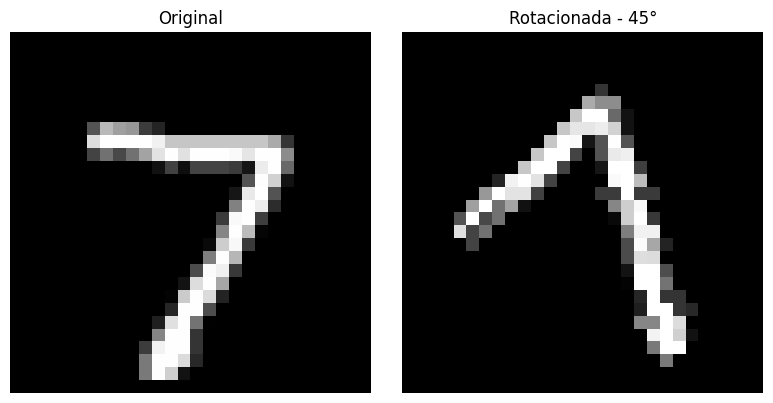

In [7]:
angulo =45

imagem_original, label = test_data.dataset[0]

imagem_rotacionada = TF.rotate(imagem_original, angle=angulo)

plt.figure(figsize=(8, 4))

plt.subplot(1, 2, 1)

plt.imshow(imagem_original.squeeze(), cmap='gray')

plt.title(f'Original')

plt.axis('off')

plt.subplot(1, 2, 2)

plt.imshow(imagem_rotacionada.squeeze(), cmap='gray')

plt.title(f'Rotacionada - {angulo}°')

plt.axis('off')

plt.tight_layout()

plt.show()

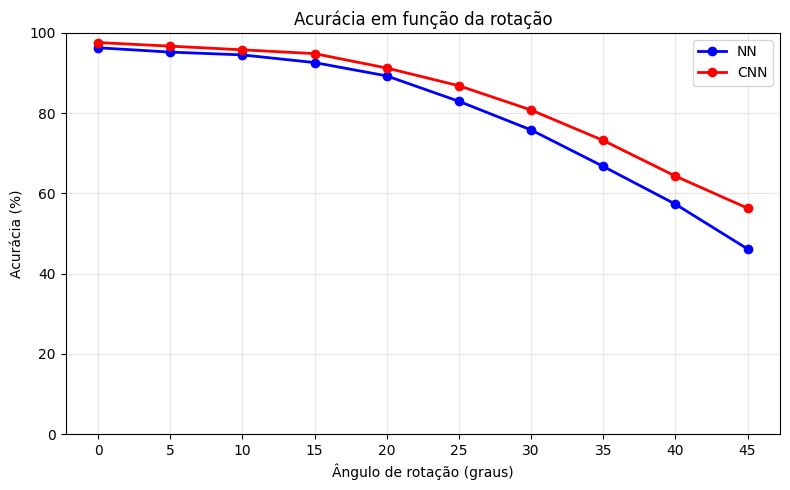

In [ ]:
acuracias_NN = []
acuracias_CNN = []
angulos = []

angulo = 0

for i in range(10):

    imagens_rotacionadas = []
    labels_rotacionados = []

    for imagem, label in test_data.dataset:
        imagem_rotacionada = TF.rotate(imagem, angle=angulo)
        imagens_rotacionadas.append(imagem_rotacionada)
        labels_rotacionados.append(label)

    imagens_rotacionadas = torch.stack(imagens_rotacionadas)
    labels_rotacionados = torch.tensor(labels_rotacionados)

    test_data_rotacionado = TensorDataset(imagens_rotacionadas, labels_rotacionados)
    test_data_rotacionado = DataLoader(test_data_rotacionado, batch_size=10)

    AcertosNoTesteRotacionado_NN = 0

    with torch.no_grad():
        for x_test, y_test in test_data_rotacionado:
            y_pred = model_nn(x_test)
            predicted = torch.argmax(y_pred, dim=1)

            AcertosNoTesteRotacionado_NN += (predicted == y_test).sum()

    AcuraciaNoTesteRotacionado_NN = (AcertosNoTesteRotacionado_NN.item() / len(test_data_rotacionado.dataset)) * 100

    AcertosNoTesteRotacionado_CNN = 0

    with torch.no_grad():
        for x_test, y_test in test_data_rotacionado:
            y_pred = model_cnn(x_test)
            predicted = torch.argmax(y_pred, dim=1)

            AcertosNoTesteRotacionado_CNN += (predicted == y_test).sum()

    AcuraciaNoTesteRotacionado_CNN = (AcertosNoTesteRotacionado_CNN.item() / len(test_data_rotacionado.dataset)) * 100

    angulos.append(angulo)
    acuracias_NN.append(AcuraciaNoTesteRotacionado_NN)
    acuracias_CNN.append(AcuraciaNoTesteRotacionado_CNN)

    angulo += 5


plt.figure(figsize=(8, 5))

plt.plot(angulos, acuracias_NN, marker='o', linewidth=2, color='blue', label='NN')
plt.plot(angulos, acuracias_CNN, marker='o', linewidth=2, color='red', label='CNN')

plt.title('Acurácia em função da rotação')
plt.xlabel('Ângulo de rotação (graus)')
plt.ylabel('Acurácia (%)')

plt.xticks(angulos)
plt.ylim(0, 100)

plt.grid(True, alpha=0.3)
plt.legend()

plt.tight_layout()
plt.show()

## Usando pequenas quantidades de imagens por classe:

Quantidade de imagens de treino por classe: 50
Acurácia NN: 29.73%
Acurácia CNN: 14.81%

Quantidade de imagens de treino por classe: 100
Acurácia NN: 49.29%
Acurácia CNN: 13.90%

Quantidade de imagens de treino por classe: 150
Acurácia NN: 79.25%
Acurácia CNN: 45.05%

Quantidade de imagens de treino por classe: 200
Acurácia NN: 81.00%
Acurácia CNN: 44.41%

Quantidade de imagens de treino por classe: 250
Acurácia NN: 85.10%
Acurácia CNN: 62.08%

Quantidade de imagens de treino por classe: 300
Acurácia NN: 86.09%
Acurácia CNN: 89.13%

Quantidade de imagens de treino por classe: 350
Acurácia NN: 86.22%
Acurácia CNN: 88.02%

Quantidade de imagens de treino por classe: 400
Acurácia NN: 89.33%
Acurácia CNN: 90.58%

Quantidade de imagens de treino por classe: 450
Acurácia NN: 89.00%
Acurácia CNN: 90.47%

Quantidade de imagens de treino por classe: 500
Acurácia NN: 90.63%
Acurácia CNN: 92.43%



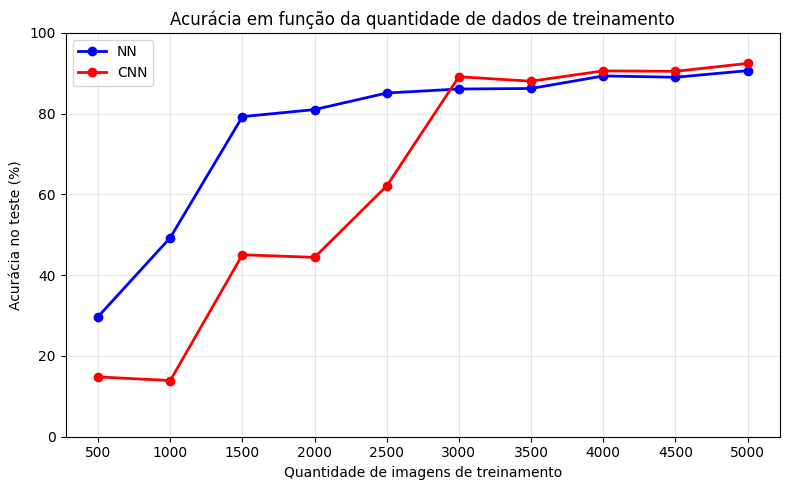

In [ ]:
quantidades_treino = []
acuracias_NN = []
acuracias_CNN = []

quantidade_por_classe = 50

indices_por_classe = {i: [] for i in range(10)}

meu_subset = train_data.dataset
dataset_original = meu_subset.dataset
indices_do_subset = meu_subset.indices

targets_originais = dataset_original.targets

for i, indice_real in enumerate(indices_do_subset):
    y = int(targets_originais[indice_real])
    indices_por_classe[y].append(i)


for experimento in range(10):

    print(f'Quantidade de imagens de treino por classe: {quantidade_por_classe}')

    indices = []

    for classe in range(10):
        indices.extend(indices_por_classe[classe][:quantidade_por_classe])

    dados_treino = torch.utils.data.Subset(train_data.dataset, indices)
    dados_treino = DataLoader(dados_treino, batch_size=10, shuffle=True)

    model_nn_experimento = NN(28*28, 10)

    criterion = nn.CrossEntropyLoss()
    optimizer = torch.optim.SGD(model_nn_experimento.parameters(), lr=0.01)

    epochs = 10

    for i in range(epochs):

        for x_train, y_train in dados_treino:

            y_pred = model_nn_experimento(x_train)
            loss = criterion(y_pred, y_train)

            optimizer.zero_grad()
            loss.backward()
            optimizer.step()


    AcertosNoTeste_NN = 0

    with torch.no_grad():

        for x_test, y_test in test_data:

            y_pred = model_nn_experimento(x_test)
            predicted = torch.argmax(y_pred, dim=1)

            AcertosNoTeste_NN += (predicted == y_test).sum()

    AcuraciaNoTeste_NN = (AcertosNoTeste_NN.item() / len(test_data.dataset)) * 100


    model_cnn_experimento = CNN(10,1,28)

    criterion = nn.CrossEntropyLoss()
    optimizer = torch.optim.SGD(model_cnn_experimento.parameters(), lr=0.01)

    for i in range(epochs):

        for x_train, y_train in dados_treino:

            y_pred = model_cnn_experimento(x_train)
            loss = criterion(y_pred, y_train)

            optimizer.zero_grad()
            loss.backward()
            optimizer.step()


    AcertosNoTeste_CNN = 0

    with torch.no_grad():

        for x_test, y_test in test_data:

            y_pred = model_cnn_experimento(x_test)
            predicted = torch.argmax(y_pred, dim=1)

            AcertosNoTeste_CNN += (predicted == y_test).sum()

    AcuraciaNoTeste_CNN = (AcertosNoTeste_CNN.item() / len(test_data.dataset)) * 100


    quantidade_total = quantidade_por_classe * 10

    quantidades_treino.append(quantidade_total)
    acuracias_NN.append(AcuraciaNoTeste_NN)
    acuracias_CNN.append(AcuraciaNoTeste_CNN)

    print(f'Acurácia NN: {AcuraciaNoTeste_NN:.2f}%')
    print(f'Acurácia CNN: {AcuraciaNoTeste_CNN:.2f}%')
    print()

    quantidade_por_classe += 50


plt.figure(figsize=(8, 5))

plt.plot(quantidades_treino, acuracias_NN, marker='o', linewidth=2, color='blue', label='NN')
plt.plot(quantidades_treino, acuracias_CNN, marker='o', linewidth=2, color='red', label='CNN')

plt.title('Acurácia em função da quantidade de dados de treinamento')
plt.xlabel('Quantidade de imagens de treinamento')
plt.ylabel('Acurácia no teste (%)')

plt.xticks(quantidades_treino)
plt.ylim(0, 100)

plt.grid(True, alpha=0.3)
plt.legend()

plt.tight_layout()
plt.show()

# Treinando e testando CNN e NN usando o dataset CIFAR 10

## Carregando o dataset:

In [ ]:
transform_NN = transforms.ToTensor()

train_data = datasets.CIFAR10(root='/', train=True, download=True, transform=transform_NN)
test_data = datasets.CIFAR10(root='/', train=False, download=True, transform=transform_NN)

train_size = int(0.8 * len(train_data))
val_size = len(train_data) - train_size

train_data, validation_data = random_split(train_data, [train_size, val_size], generator=torch.Generator().manual_seed(seed))

# Batch size de 10
train_data = DataLoader(train_data, batch_size=10)
test_data = DataLoader(test_data, batch_size=10)
validation_data = DataLoader(validation_data, batch_size=10)


## Treinando e testando a NN:

In [ ]:
model_nn_cifar10 = NN(3 * 32 * 32, 10)

criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.SGD(model_nn_cifar10.parameters(), lr=0.01)

patience = 3
delta = 0.01
melhor_loss_validacao = float('inf')
epochs_sem_melhora = 0

epochs = 50
AcertosEmCadaEpoch_NN = []
LossMediaEmCadaEpoch_NN = []
AcertosEmCadaEpoch_Validacao_NN = []
LossMediaEmCadaEpoch_Validacao_NN = []
start_time_NN = time.time()

for i in range(epochs):
  AcertosNaEpoch = 0
  SomaLossNaEpoch = 0


  # treino
  # Passa pelos batches
  for b,(x_train, y_train) in enumerate(train_data):
    y_pred = model_nn_cifar10(x_train)
    loss = criterion(y_pred, y_train)


    predicted = torch.argmax(y_pred, dim=1)
    acertosNoBatch = (predicted == y_train).sum()
    AcertosNaEpoch += acertosNoBatch
    SomaLossNaEpoch += loss.item()

    optimizer.zero_grad()
    loss.backward()
    optimizer.step()


    if b%600 == 0:
      print(f'Epoch: {i+1}  Batch: {b}  Loss: {loss.item()}')

  AcertosEmCadaEpoch_NN.append(AcertosNaEpoch)
  LossMediaEmCadaEpoch_NN.append(SomaLossNaEpoch/len(train_data))
  ###

  # Validacao
  AcertosNaValidacao = 0
  SomaLossNaValidacao = 0

  # Pra nao modificar o treino
  with torch.no_grad():

      # Passa pelos batches
      for x_validation, y_validation in validation_data:
          y_pred = model_nn_cifar10(x_validation)
          loss = criterion(y_pred, y_validation)

          predicted = torch.argmax(y_pred, dim=1)

          acertosNoBatch = (predicted == y_validation).sum()
          AcertosNaValidacao += acertosNoBatch
          SomaLossNaValidacao += loss.item()

  LossValidacaoAtual = SomaLossNaValidacao / len(validation_data)
  AcertosEmCadaEpoch_Validacao_NN.append(AcertosNaValidacao)
  LossMediaEmCadaEpoch_Validacao_NN.append(LossValidacaoAtual)

  if melhor_loss_validacao - LossValidacaoAtual > delta:
    melhor_loss_validacao = LossValidacaoAtual
    epochs_sem_melhora = 0
  else:
    epochs_sem_melhora += 1

  if epochs_sem_melhora >= patience:
    print(f'Early Stopping na epoch {i+1}')
    break

######  Fim do laco das epocas

current_time_NN = time.time()
total_time_NN = current_time_NN - start_time_NN
epocas_NN = len(AcertosEmCadaEpoch_NN)

# Teste
AcertosNoTest = 0
SomaLossNoTeste = 0
with torch.no_grad():
  for b,(x_test, y_test) in enumerate(test_data):
    y_pred = model_nn_cifar10(x_test)
    predicted = torch.argmax(y_pred, dim=1)
    loss = criterion(y_pred, y_test)
    SomaLossNoTeste += loss.item()
    AcertosNoBacth = (predicted == y_test).sum()
    AcertosNoTest += AcertosNoBacth

LossMediaNoTeste = SomaLossNoTeste/len(test_data)

Epoch: 1  Batch: 0  Loss: 2.2895615100860596
Epoch: 1  Batch: 600  Loss: 2.169414520263672
Epoch: 1  Batch: 1200  Loss: 2.2634336948394775
Epoch: 1  Batch: 1800  Loss: 2.088564872741699
Epoch: 1  Batch: 2400  Loss: 2.0655064582824707
Epoch: 1  Batch: 3000  Loss: 1.6087032556533813
Epoch: 1  Batch: 3600  Loss: 2.0010952949523926
Epoch: 2  Batch: 0  Loss: 1.8125369548797607
Epoch: 2  Batch: 600  Loss: 1.5207760334014893
Epoch: 2  Batch: 1200  Loss: 2.3157832622528076
Epoch: 2  Batch: 1800  Loss: 2.181751251220703
Epoch: 2  Batch: 2400  Loss: 1.7728664875030518
Epoch: 2  Batch: 3000  Loss: 1.3564560413360596
Epoch: 2  Batch: 3600  Loss: 1.8287248611450195
Epoch: 3  Batch: 0  Loss: 1.6054168939590454
Epoch: 3  Batch: 600  Loss: 1.4167662858963013
Epoch: 3  Batch: 1200  Loss: 2.2812530994415283
Epoch: 3  Batch: 1800  Loss: 2.222865104675293
Epoch: 3  Batch: 2400  Loss: 1.6449142694473267
Epoch: 3  Batch: 3000  Loss: 1.2133368253707886
Epoch: 3  Batch: 3600  Loss: 1.661283254623413
Epoch: 4 

In [ ]:
print(f'Loss media no teste: {LossMediaNoTeste}')
print(f'Acertos no test: {AcertosNoTest}')
AcuraciaNoTeste = (AcertosNoTest.item() / len(test_data.dataset)) * 100
print(f'Acurácia no teste: {AcuraciaNoTeste:.2f}%')
print(f'Tempo ate a convergencia: {total_time_NN} segundos')
print(f'Numero de epocas ate a convergencia: {epocas_NN}')

Loss media no teste: 1.4999292447566985
Acertos no test: 4640
Acurácia no teste: 46.40%
Tempo ate a convergencia: 138.07843899726868 segundos
Numero de epocas ate a convergencia: 13


### Visualizando resultados

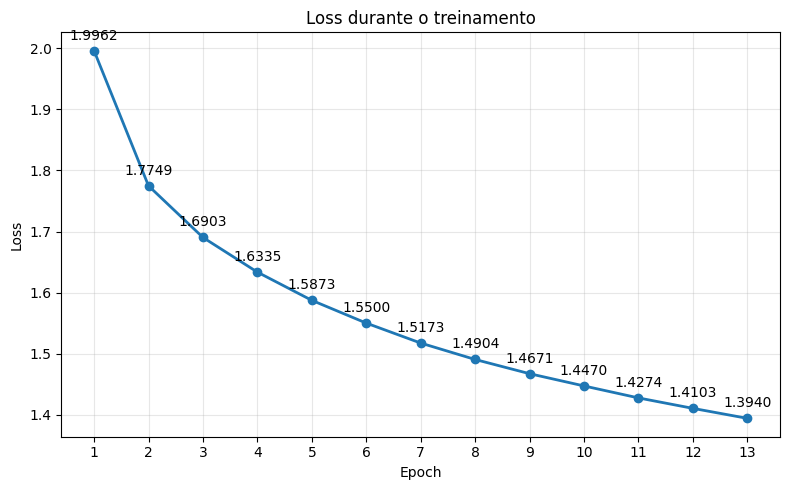

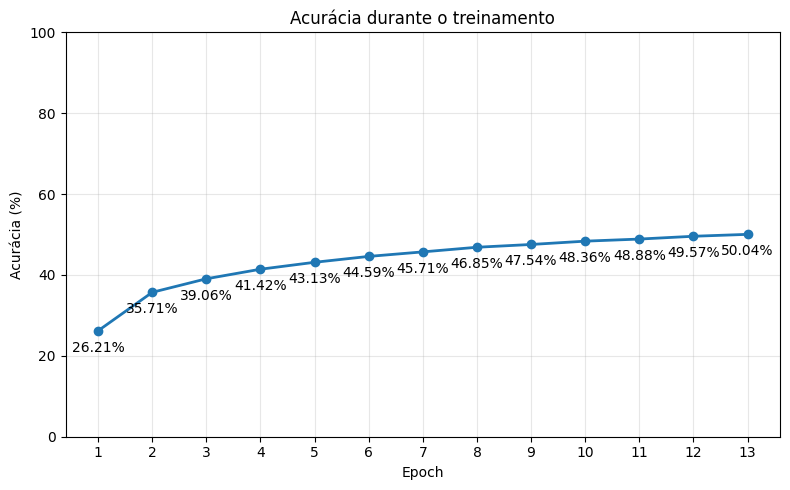

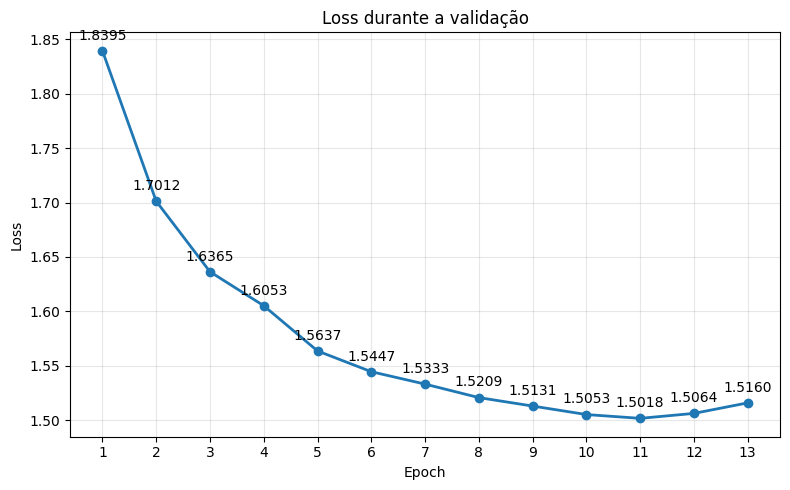

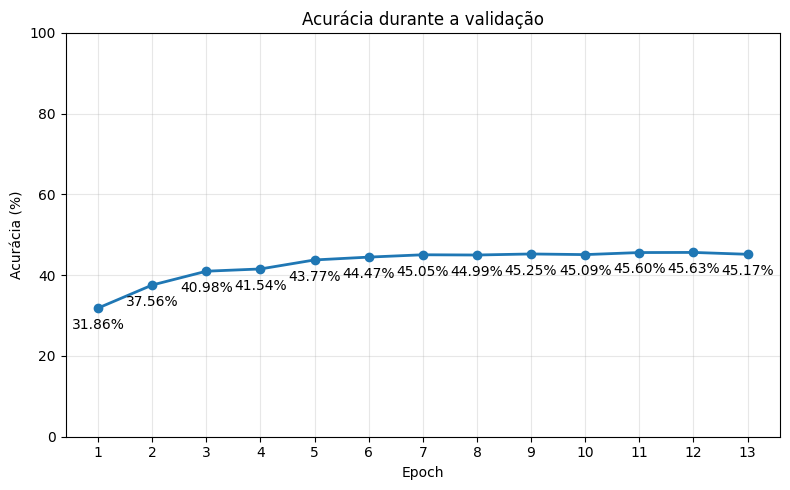

In [ ]:
total_amostras_treino = len(train_data.dataset)
total_amostras_validacao = len(validation_data.dataset)

AcuraciaEmCadaEpoch_NN = []
AcuraciaValidacaoEmCadaEpoch_NN = []

for acertos in AcertosEmCadaEpoch_NN:
    acuracia = (acertos.item() / total_amostras_treino) * 100
    AcuraciaEmCadaEpoch_NN.append(acuracia)

for acertos in AcertosEmCadaEpoch_Validacao_NN:
    acuracia = (acertos.item() / total_amostras_validacao) * 100
    AcuraciaValidacaoEmCadaEpoch_NN.append(acuracia)

epochs_lista = range(1, epocas_NN + 1)


## Treino
plt.figure(figsize=(8, 5))

plt.plot(epochs_lista, LossMediaEmCadaEpoch_NN, marker='o', linewidth=2)

for i in range(len(LossMediaEmCadaEpoch_NN)):
    plt.annotate(f'{LossMediaEmCadaEpoch_NN[i]:.4f}', (epochs_lista[i], LossMediaEmCadaEpoch_NN[i]), xytext=(0, 8), textcoords='offset points', ha='center')

plt.title('Loss durante o treinamento')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.xticks(epochs_lista)
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


plt.figure(figsize=(8, 5))

plt.plot(epochs_lista, AcuraciaEmCadaEpoch_NN, marker='o', linewidth=2)

for i in range(len(AcuraciaEmCadaEpoch_NN)):
    plt.annotate(f'{AcuraciaEmCadaEpoch_NN[i]:.2f}%', (epochs_lista[i], AcuraciaEmCadaEpoch_NN[i]), xytext=(0, -15), textcoords='offset points', ha='center')

plt.title('Acurácia durante o treinamento')
plt.xlabel('Epoch')
plt.ylabel('Acurácia (%)')
plt.xticks(epochs_lista)
plt.ylim(0, 100)
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

##

## Validacao

plt.figure(figsize=(8, 5))

plt.plot(epochs_lista, LossMediaEmCadaEpoch_Validacao_NN, marker='o', linewidth=2)

for i in range(len(LossMediaEmCadaEpoch_Validacao_NN)):
    plt.annotate(f'{LossMediaEmCadaEpoch_Validacao_NN[i]:.4f}', (epochs_lista[i], LossMediaEmCadaEpoch_Validacao_NN[i]), xytext=(0, 8), textcoords='offset points', ha='center')

plt.title('Loss durante a validação')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.xticks(epochs_lista)
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


plt.figure(figsize=(8, 5))

plt.plot(epochs_lista, AcuraciaValidacaoEmCadaEpoch_NN, marker='o', linewidth=2)

for i in range(len(AcuraciaValidacaoEmCadaEpoch_NN)):
    plt.annotate(f'{AcuraciaValidacaoEmCadaEpoch_NN[i]:.2f}%', (epochs_lista[i], AcuraciaValidacaoEmCadaEpoch_NN[i]), xytext=(0, -15), textcoords='offset points', ha='center')

plt.title('Acurácia durante a validação')
plt.xlabel('Epoch')
plt.ylabel('Acurácia (%)')
plt.xticks(epochs_lista)
plt.ylim(0, 100)
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

##


## Treinando e testando a CNN:

In [ ]:
model_cnn_cifar10 = CNN(10,3, 32)

criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.SGD(model_cnn_cifar10.parameters(), lr=0.01)

patience = 3
delta = 0.01
melhor_loss_validacao = float('inf')
epochs_sem_melhora = 0

epochs = 50
AcertosEmCadaEpoch_CNN = []
LossMediaEmCadaEpoch_CNN = []
AcertosEmCadaEpoch_Validacao_CNN = []
LossMediaEmCadaEpoch_Validacao_CNN = []
start_time_CNN = time.time()

for i in range(epochs):
  AcertosNaEpoch = 0
  SomaLossNaEpoch = 0


  # Train
  for b,(x_train, y_train) in enumerate(train_data):
    y_pred = model_cnn_cifar10(x_train)
    loss = criterion(y_pred, y_train)

    predicted = torch.argmax(y_pred, dim=1)
    acertosNoBatch = (predicted == y_train).sum()
    AcertosNaEpoch += acertosNoBatch
    SomaLossNaEpoch += loss.item()

    optimizer.zero_grad()
    loss.backward()
    optimizer.step()


    if b%600 == 0:
      print(f'Epoch: {i+1}  Batch: {b}  Loss: {loss.item()}')

  AcertosEmCadaEpoch_CNN.append(AcertosNaEpoch)
  LossMediaEmCadaEpoch_CNN.append(SomaLossNaEpoch/len(train_data))


  # Validation
  AcertosNaValidacao = 0
  SomaLossNaValidacao = 0

  with torch.no_grad():
      for x_validation, y_validation in validation_data:
          y_pred = model_cnn_cifar10(x_validation)
          loss = criterion(y_pred, y_validation)

          predicted = torch.argmax(y_pred, dim=1)

          acertosNoBatch = (predicted == y_validation).sum()
          AcertosNaValidacao += acertosNoBatch
          SomaLossNaValidacao += loss.item()

  LossValidacaoAtual = SomaLossNaValidacao / len(validation_data)
  AcertosEmCadaEpoch_Validacao_CNN.append(AcertosNaValidacao)
  LossMediaEmCadaEpoch_Validacao_CNN.append(LossValidacaoAtual)

  if melhor_loss_validacao - LossValidacaoAtual > delta:
    melhor_loss_validacao = LossValidacaoAtual
    epochs_sem_melhora = 0
  else:
    epochs_sem_melhora += 1

  if epochs_sem_melhora >= patience:
    print(f'Early Stopping na epoch {i+1}')
    break


current_time_CNN = time.time()
total_time_CNN = current_time_CNN - start_time_CNN
epocas_CNN = len(AcertosEmCadaEpoch_CNN)

# Test
AcertosNoTest = 0
SomaLossNoTeste = 0
with torch.no_grad():
  for b,(x_test, y_test) in enumerate(test_data):
    y_pred = model_cnn_cifar10(x_test)
    predicted = torch.argmax(y_pred, dim=1)
    loss = criterion(y_pred, y_test)
    SomaLossNoTeste += loss.item()
    AcertosNoBacth = (predicted == y_test).sum()
    AcertosNoTest += AcertosNoBacth

LossMediaNoTeste = SomaLossNoTeste/len(test_data)

Epoch: 1  Batch: 0  Loss: 2.3333306312561035
Epoch: 1  Batch: 600  Loss: 2.2906908988952637
Epoch: 1  Batch: 1200  Loss: 2.3071765899658203
Epoch: 1  Batch: 1800  Loss: 2.300985813140869
Epoch: 1  Batch: 2400  Loss: 2.314593553543091
Epoch: 1  Batch: 3000  Loss: 2.2903223037719727
Epoch: 1  Batch: 3600  Loss: 2.305349826812744
Epoch: 2  Batch: 0  Loss: 2.2609305381774902
Epoch: 2  Batch: 600  Loss: 2.2131662368774414
Epoch: 2  Batch: 1200  Loss: 2.1497912406921387
Epoch: 2  Batch: 1800  Loss: 1.9899280071258545
Epoch: 2  Batch: 2400  Loss: 2.194993734359741
Epoch: 2  Batch: 3000  Loss: 1.9088127613067627
Epoch: 2  Batch: 3600  Loss: 1.8455712795257568
Epoch: 3  Batch: 0  Loss: 2.0063328742980957
Epoch: 3  Batch: 600  Loss: 1.3930095434188843
Epoch: 3  Batch: 1200  Loss: 2.0361216068267822
Epoch: 3  Batch: 1800  Loss: 2.1550488471984863
Epoch: 3  Batch: 2400  Loss: 1.7437107563018799
Epoch: 3  Batch: 3000  Loss: 1.4550435543060303
Epoch: 3  Batch: 3600  Loss: 1.8083953857421875
Epoch: 4

In [ ]:
print(f'Loss media no teste: {LossMediaNoTeste}')
print(f'Acertos no test: {AcertosNoTest}')
AcuraciaNoTeste = (AcertosNoTest.item() / len(test_data.dataset)) * 100
print(f'Acurácia no teste: {AcuraciaNoTeste:.2f}%')
print(f'Tempo ate a convergencia: {total_time_CNN} segundos')
print(f'Numero de epocas ate a convergencia: {epocas_CNN}')

Loss media no teste: 1.1035414258092642
Acertos no test: 6526
Acurácia no teste: 65.26%
Tempo ate a convergencia: 829.4822549819946 segundos
Numero de epocas ate a convergencia: 16


### Visualizando os resultados:

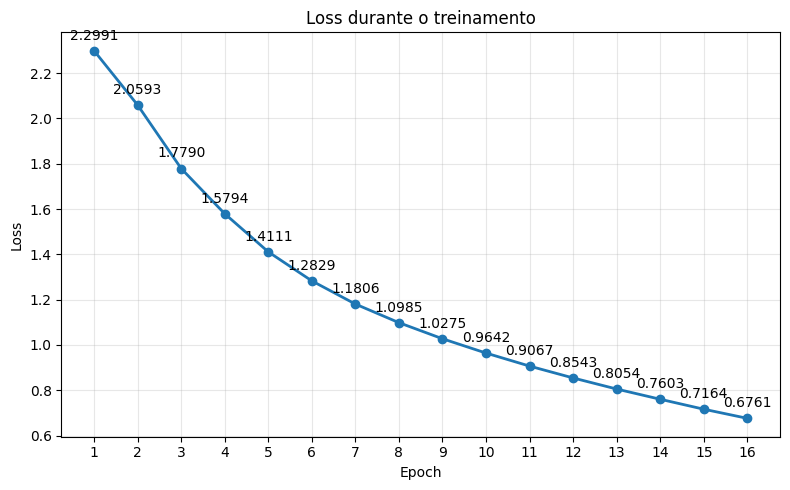

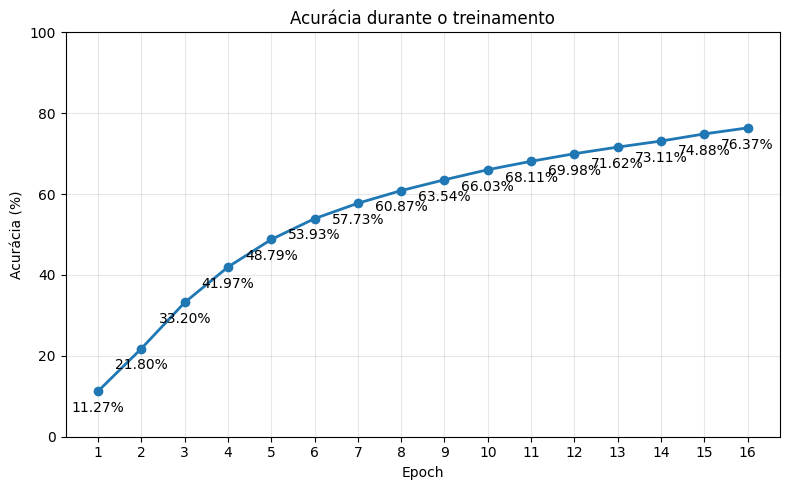

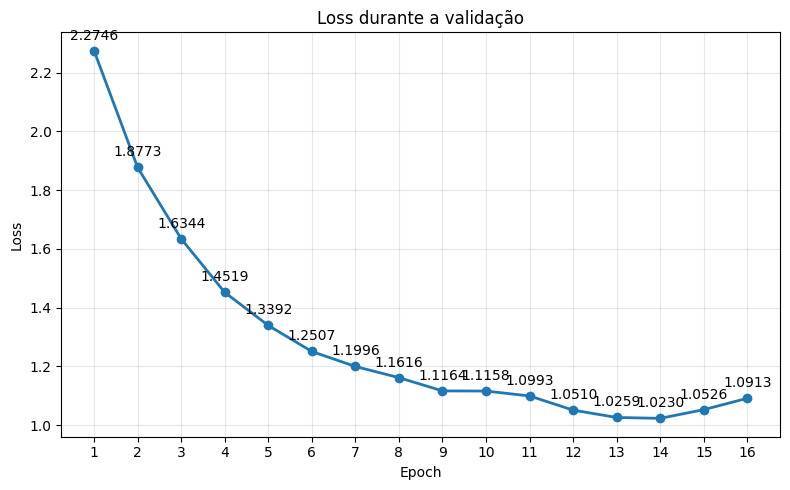

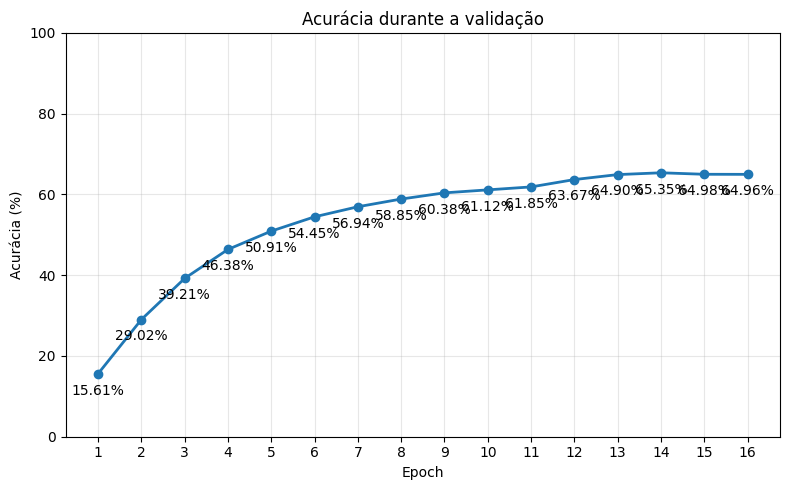

In [ ]:
total_amostras_treino = len(train_data.dataset)
total_amostras_validacao = len(validation_data.dataset)

AcuraciaEmCadaEpoch_CNN = []
AcuraciaValidacaoEmCadaEpoch_CNN = []

for acertos in AcertosEmCadaEpoch_CNN:
    acuracia = (acertos.item() / total_amostras_treino) * 100
    AcuraciaEmCadaEpoch_CNN.append(acuracia)

for acertos in AcertosEmCadaEpoch_Validacao_CNN:
    acuracia = (acertos.item() / total_amostras_validacao) * 100
    AcuraciaValidacaoEmCadaEpoch_CNN.append(acuracia)

epochs_lista = range(1, epocas_CNN + 1)

plt.figure(figsize=(8, 5))

plt.plot(epochs_lista, LossMediaEmCadaEpoch_CNN, marker='o', linewidth=2)

for i in range(len(LossMediaEmCadaEpoch_CNN)):
    plt.annotate(f'{LossMediaEmCadaEpoch_CNN[i]:.4f}', (epochs_lista[i], LossMediaEmCadaEpoch_CNN[i]), xytext=(0, 8), textcoords='offset points', ha='center')

plt.title('Loss durante o treinamento')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.xticks(epochs_lista)
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


plt.figure(figsize=(8, 5))

plt.plot(epochs_lista, AcuraciaEmCadaEpoch_CNN, marker='o', linewidth=2)

for i in range(len(AcuraciaEmCadaEpoch_CNN)):
    plt.annotate(f'{AcuraciaEmCadaEpoch_CNN[i]:.2f}%', (epochs_lista[i], AcuraciaEmCadaEpoch_CNN[i]), xytext=(0, -15), textcoords='offset points', ha='center')

plt.title('Acurácia durante o treinamento')
plt.xlabel('Epoch')
plt.ylabel('Acurácia (%)')
plt.xticks(epochs_lista)
plt.ylim(0, 100)
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()



## Validacao

plt.figure(figsize=(8, 5))

plt.plot(epochs_lista, LossMediaEmCadaEpoch_Validacao_CNN, marker='o', linewidth=2)

for i in range(len(LossMediaEmCadaEpoch_Validacao_CNN)):
    plt.annotate(f'{LossMediaEmCadaEpoch_Validacao_CNN[i]:.4f}', (epochs_lista[i], LossMediaEmCadaEpoch_Validacao_CNN[i]), xytext=(0, 8), textcoords='offset points', ha='center')

plt.title('Loss durante a validação')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.xticks(epochs_lista)
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


plt.figure(figsize=(8, 5))

plt.plot(epochs_lista, AcuraciaValidacaoEmCadaEpoch_CNN, marker='o', linewidth=2)

for i in range(len(AcuraciaValidacaoEmCadaEpoch_CNN)):
    plt.annotate(f'{AcuraciaValidacaoEmCadaEpoch_CNN[i]:.2f}%', (epochs_lista[i], AcuraciaValidacaoEmCadaEpoch_CNN[i]), xytext=(0, -15), textcoords='offset points', ha='center')

plt.title('Acurácia durante a validação')
plt.xlabel('Epoch')
plt.ylabel('Acurácia (%)')
plt.xticks(epochs_lista)
plt.ylim(0, 100)
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

##



# Modificando hiperparâmetros considerando CNN e NN usando o dataset CIFAR 10:

## Treinando e testando a NN usando otimizador Adam:

In [ ]:
model_nn_cifar10 = NN(3 * 32 * 32, 10)

criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model_nn_cifar10.parameters(), lr=0.01)

patience = 3
delta = 0.01
melhor_loss_validacao = float('inf')
epochs_sem_melhora = 0

epochs = 50
AcertosEmCadaEpoch_NN = []
LossMediaEmCadaEpoch_NN = []
AcertosEmCadaEpoch_Validacao_NN = []
LossMediaEmCadaEpoch_Validacao_NN = []
start_time_NN = time.time()

for i in range(epochs):
  AcertosNaEpoch = 0
  SomaLossNaEpoch = 0


  # treino
  # Passa pelos batches
  for b,(x_train, y_train) in enumerate(train_data):
    y_pred = model_nn_cifar10(x_train)
    loss = criterion(y_pred, y_train)


    predicted = torch.argmax(y_pred, dim=1)
    acertosNoBatch = (predicted == y_train).sum()
    AcertosNaEpoch += acertosNoBatch
    SomaLossNaEpoch += loss.item()

    optimizer.zero_grad()
    loss.backward()
    optimizer.step()


    if b%600 == 0:
      print(f'Epoch: {i+1}  Batch: {b}  Loss: {loss.item()}')

  AcertosEmCadaEpoch_NN.append(AcertosNaEpoch)
  LossMediaEmCadaEpoch_NN.append(SomaLossNaEpoch/len(train_data))
  ###

  # Validacao
  AcertosNaValidacao = 0
  SomaLossNaValidacao = 0

  # Pra nao modificar o treino
  with torch.no_grad():

      # Passa pelos batches
      for x_validation, y_validation in validation_data:
          y_pred = model_nn_cifar10(x_validation)
          loss = criterion(y_pred, y_validation)

          predicted = torch.argmax(y_pred, dim=1)

          acertosNoBatch = (predicted == y_validation).sum()
          AcertosNaValidacao += acertosNoBatch
          SomaLossNaValidacao += loss.item()

  LossValidacaoAtual = SomaLossNaValidacao / len(validation_data)
  AcertosEmCadaEpoch_Validacao_NN.append(AcertosNaValidacao)
  LossMediaEmCadaEpoch_Validacao_NN.append(LossValidacaoAtual)

  if melhor_loss_validacao - LossValidacaoAtual > delta:
    melhor_loss_validacao = LossValidacaoAtual
    epochs_sem_melhora = 0
  else:
    epochs_sem_melhora += 1

  if epochs_sem_melhora >= patience:
    print(f'Early Stopping na epoch {i+1}')
    break

######  Fim do laco das epocas

current_time_NN = time.time()
total_time_NN = current_time_NN - start_time_NN
epocas_NN = len(AcertosEmCadaEpoch_NN)

# Teste
AcertosNoTest = 0
SomaLossNoTeste = 0
with torch.no_grad():
  for b,(x_test, y_test) in enumerate(test_data):
    y_pred = model_nn_cifar10(x_test)
    predicted = torch.argmax(y_pred, dim=1)
    loss = criterion(y_pred, y_test)
    SomaLossNoTeste += loss.item()
    AcertosNoBacth = (predicted == y_test).sum()
    AcertosNoTest += AcertosNoBacth

LossMediaNoTeste = SomaLossNoTeste/len(test_data)

Epoch: 1  Batch: 0  Loss: 2.288313388824463
Epoch: 1  Batch: 600  Loss: 2.1443018913269043
Epoch: 1  Batch: 1200  Loss: 2.322467565536499
Epoch: 1  Batch: 1800  Loss: 2.115232229232788
Epoch: 1  Batch: 2400  Loss: 2.1601815223693848
Epoch: 1  Batch: 3000  Loss: 1.888382911682129
Epoch: 1  Batch: 3600  Loss: 2.1324374675750732
Epoch: 2  Batch: 0  Loss: 1.8887884616851807
Epoch: 2  Batch: 600  Loss: 1.9451252222061157
Epoch: 2  Batch: 1200  Loss: 2.3669466972351074
Epoch: 2  Batch: 1800  Loss: 2.162992000579834
Epoch: 2  Batch: 2400  Loss: 2.1618475914001465
Epoch: 2  Batch: 3000  Loss: 1.9415584802627563
Epoch: 2  Batch: 3600  Loss: 1.971961259841919
Epoch: 3  Batch: 0  Loss: 1.85421884059906
Epoch: 3  Batch: 600  Loss: 2.027236223220825
Epoch: 3  Batch: 1200  Loss: 2.244823694229126
Epoch: 3  Batch: 1800  Loss: 2.1182656288146973
Epoch: 3  Batch: 2400  Loss: 2.0943069458007812
Epoch: 3  Batch: 3000  Loss: 1.9204967021942139
Epoch: 3  Batch: 3600  Loss: 2.2147789001464844
Epoch: 4  Batc

In [ ]:
print(f'Loss media no teste: {LossMediaNoTeste}')
print(f'Acertos no test: {AcertosNoTest}')
AcuraciaNoTeste = (AcertosNoTest.item() / len(test_data.dataset)) * 100
print(f'Acurácia no teste: {AcuraciaNoTeste:.2f}%')
print(f'Tempo ate a convergencia: {total_time_NN} segundos')
print(f'Numero de epocas ate a convergencia: {epocas_NN}')

Loss media no teste: 2.070719077706337
Acertos no test: 1888
Acurácia no teste: 18.88%
Tempo ate a convergencia: 59.09308218955994 segundos
Numero de epocas ate a convergencia: 4


### Visualizando resultados

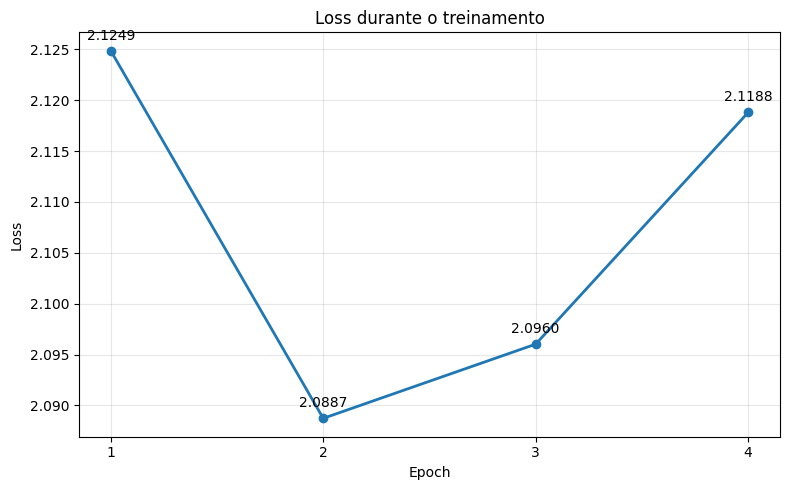

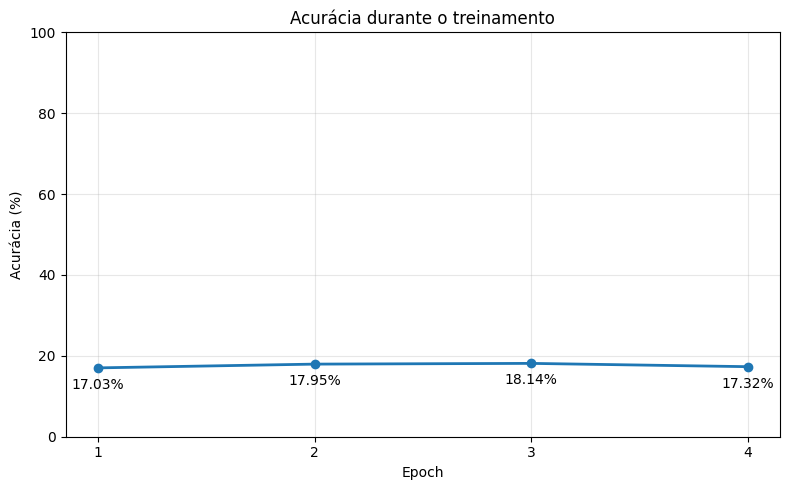

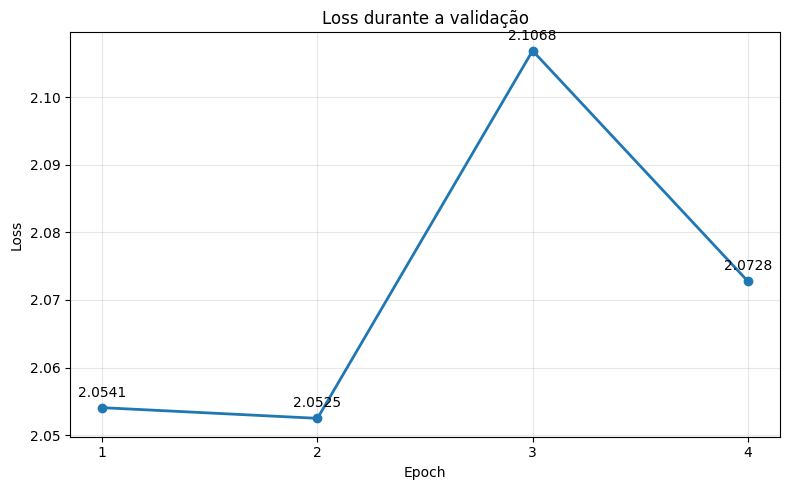

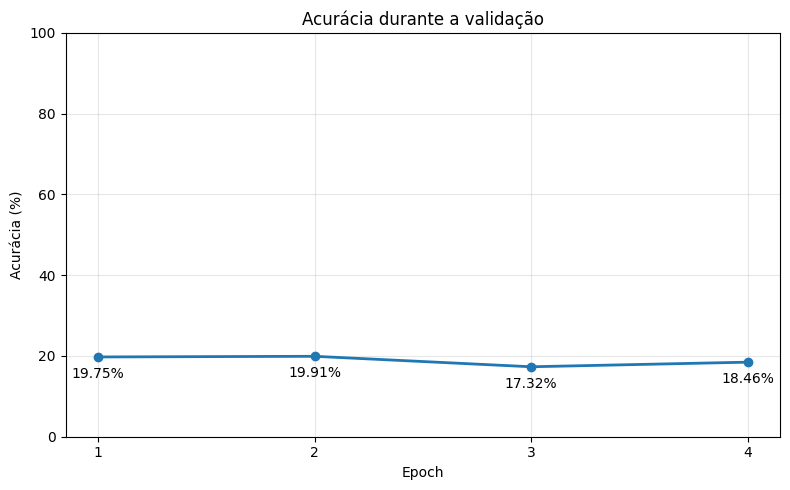

In [ ]:
total_amostras_treino = len(train_data.dataset)
total_amostras_validacao = len(validation_data.dataset)

AcuraciaEmCadaEpoch_NN = []
AcuraciaValidacaoEmCadaEpoch_NN = []

for acertos in AcertosEmCadaEpoch_NN:
    acuracia = (acertos.item() / total_amostras_treino) * 100
    AcuraciaEmCadaEpoch_NN.append(acuracia)

for acertos in AcertosEmCadaEpoch_Validacao_NN:
    acuracia = (acertos.item() / total_amostras_validacao) * 100
    AcuraciaValidacaoEmCadaEpoch_NN.append(acuracia)

epochs_lista = range(1, epocas_NN + 1)


## Treino
plt.figure(figsize=(8, 5))

plt.plot(epochs_lista, LossMediaEmCadaEpoch_NN, marker='o', linewidth=2)

for i in range(len(LossMediaEmCadaEpoch_NN)):
    plt.annotate(f'{LossMediaEmCadaEpoch_NN[i]:.4f}', (epochs_lista[i], LossMediaEmCadaEpoch_NN[i]), xytext=(0, 8), textcoords='offset points', ha='center')

plt.title('Loss durante o treinamento')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.xticks(epochs_lista)
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


plt.figure(figsize=(8, 5))

plt.plot(epochs_lista, AcuraciaEmCadaEpoch_NN, marker='o', linewidth=2)

for i in range(len(AcuraciaEmCadaEpoch_NN)):
    plt.annotate(f'{AcuraciaEmCadaEpoch_NN[i]:.2f}%', (epochs_lista[i], AcuraciaEmCadaEpoch_NN[i]), xytext=(0, -15), textcoords='offset points', ha='center')

plt.title('Acurácia durante o treinamento')
plt.xlabel('Epoch')
plt.ylabel('Acurácia (%)')
plt.xticks(epochs_lista)
plt.ylim(0, 100)
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

##

## Validacao

plt.figure(figsize=(8, 5))

plt.plot(epochs_lista, LossMediaEmCadaEpoch_Validacao_NN, marker='o', linewidth=2)

for i in range(len(LossMediaEmCadaEpoch_Validacao_NN)):
    plt.annotate(f'{LossMediaEmCadaEpoch_Validacao_NN[i]:.4f}', (epochs_lista[i], LossMediaEmCadaEpoch_Validacao_NN[i]), xytext=(0, 8), textcoords='offset points', ha='center')

plt.title('Loss durante a validação')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.xticks(epochs_lista)
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


plt.figure(figsize=(8, 5))

plt.plot(epochs_lista, AcuraciaValidacaoEmCadaEpoch_NN, marker='o', linewidth=2)

for i in range(len(AcuraciaValidacaoEmCadaEpoch_NN)):
    plt.annotate(f'{AcuraciaValidacaoEmCadaEpoch_NN[i]:.2f}%', (epochs_lista[i], AcuraciaValidacaoEmCadaEpoch_NN[i]), xytext=(0, -15), textcoords='offset points', ha='center')

plt.title('Acurácia durante a validação')
plt.xlabel('Epoch')
plt.ylabel('Acurácia (%)')
plt.xticks(epochs_lista)
plt.ylim(0, 100)
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

##


## Treinando e testando a NN usando otimizador Adam e diminuindo o learning rate:

In [ ]:
model_nn_cifar10 = NN(3 * 32 * 32, 10)

criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model_nn_cifar10.parameters(), lr=0.0005)

patience = 3
delta = 0.01
melhor_loss_validacao = float('inf')
epochs_sem_melhora = 0

epochs = 50
AcertosEmCadaEpoch_NN = []
LossMediaEmCadaEpoch_NN = []
AcertosEmCadaEpoch_Validacao_NN = []
LossMediaEmCadaEpoch_Validacao_NN = []
start_time_NN = time.time()

for i in range(epochs):
  AcertosNaEpoch = 0
  SomaLossNaEpoch = 0


  # treino
  # Passa pelos batches
  for b,(x_train, y_train) in enumerate(train_data):
    y_pred = model_nn_cifar10(x_train)
    loss = criterion(y_pred, y_train)


    predicted = torch.argmax(y_pred, dim=1)
    acertosNoBatch = (predicted == y_train).sum()
    AcertosNaEpoch += acertosNoBatch
    SomaLossNaEpoch += loss.item()

    optimizer.zero_grad()
    loss.backward()
    optimizer.step()


    if b%600 == 0:
      print(f'Epoch: {i+1}  Batch: {b}  Loss: {loss.item()}')

  AcertosEmCadaEpoch_NN.append(AcertosNaEpoch)
  LossMediaEmCadaEpoch_NN.append(SomaLossNaEpoch/len(train_data))
  ###

  # Validacao
  AcertosNaValidacao = 0
  SomaLossNaValidacao = 0

  # Pra nao modificar o treino
  with torch.no_grad():

      # Passa pelos batches
      for x_validation, y_validation in validation_data:
          y_pred = model_nn_cifar10(x_validation)
          loss = criterion(y_pred, y_validation)

          predicted = torch.argmax(y_pred, dim=1)

          acertosNoBatch = (predicted == y_validation).sum()
          AcertosNaValidacao += acertosNoBatch
          SomaLossNaValidacao += loss.item()

  LossValidacaoAtual = SomaLossNaValidacao / len(validation_data)
  AcertosEmCadaEpoch_Validacao_NN.append(AcertosNaValidacao)
  LossMediaEmCadaEpoch_Validacao_NN.append(LossValidacaoAtual)

  if melhor_loss_validacao - LossValidacaoAtual > delta:
    melhor_loss_validacao = LossValidacaoAtual
    epochs_sem_melhora = 0
  else:
    epochs_sem_melhora += 1

  if epochs_sem_melhora >= patience:
    print(f'Early Stopping na epoch {i+1}')
    break

######  Fim do laco das epocas

current_time_NN = time.time()
total_time_NN = current_time_NN - start_time_NN
epocas_NN = len(AcertosEmCadaEpoch_NN)

# Teste
AcertosNoTest = 0
SomaLossNoTeste = 0
with torch.no_grad():
  for b,(x_test, y_test) in enumerate(test_data):
    y_pred = model_nn_cifar10(x_test)
    predicted = torch.argmax(y_pred, dim=1)
    loss = criterion(y_pred, y_test)
    SomaLossNoTeste += loss.item()
    AcertosNoBacth = (predicted == y_test).sum()
    AcertosNoTest += AcertosNoBacth

LossMediaNoTeste = SomaLossNoTeste/len(test_data)

Epoch: 1  Batch: 0  Loss: 2.312077045440674
Epoch: 1  Batch: 600  Loss: 1.7310130596160889
Epoch: 1  Batch: 1200  Loss: 2.5345771312713623
Epoch: 1  Batch: 1800  Loss: 2.189807176589966
Epoch: 1  Batch: 2400  Loss: 1.720658540725708
Epoch: 1  Batch: 3000  Loss: 1.6134274005889893
Epoch: 1  Batch: 3600  Loss: 1.886296033859253
Epoch: 2  Batch: 0  Loss: 1.622584342956543
Epoch: 2  Batch: 600  Loss: 1.4391206502914429
Epoch: 2  Batch: 1200  Loss: 2.5008156299591064
Epoch: 2  Batch: 1800  Loss: 2.1559336185455322
Epoch: 2  Batch: 2400  Loss: 1.5969822406768799
Epoch: 2  Batch: 3000  Loss: 1.3358824253082275
Epoch: 2  Batch: 3600  Loss: 1.7712934017181396
Epoch: 3  Batch: 0  Loss: 1.4677388668060303
Epoch: 3  Batch: 600  Loss: 1.4887641668319702
Epoch: 3  Batch: 1200  Loss: 2.3604705333709717
Epoch: 3  Batch: 1800  Loss: 2.107067823410034
Epoch: 3  Batch: 2400  Loss: 1.5506620407104492
Epoch: 3  Batch: 3000  Loss: 1.276390790939331
Epoch: 3  Batch: 3600  Loss: 1.7363706827163696
Epoch: 4  B

In [ ]:
print(f'Loss media no teste: {LossMediaNoTeste}')
print(f'Acertos no test: {AcertosNoTest}')
AcuraciaNoTeste = (AcertosNoTest.item() / len(test_data.dataset)) * 100
print(f'Acurácia no teste: {AcuraciaNoTeste:.2f}%')
print(f'Tempo ate a convergencia: {total_time_NN} segundos')
print(f'Numero de epocas ate a convergencia: {epocas_NN}')

Loss media no teste: 1.531614333331585
Acertos no test: 4547
Acurácia no teste: 45.47%
Tempo ate a convergencia: 231.44556736946106 segundos
Numero de epocas ate a convergencia: 16


### Visualizando resultados

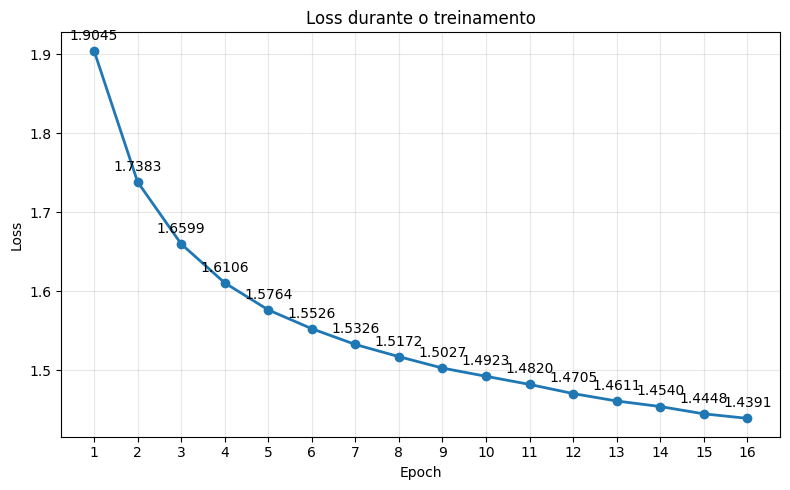

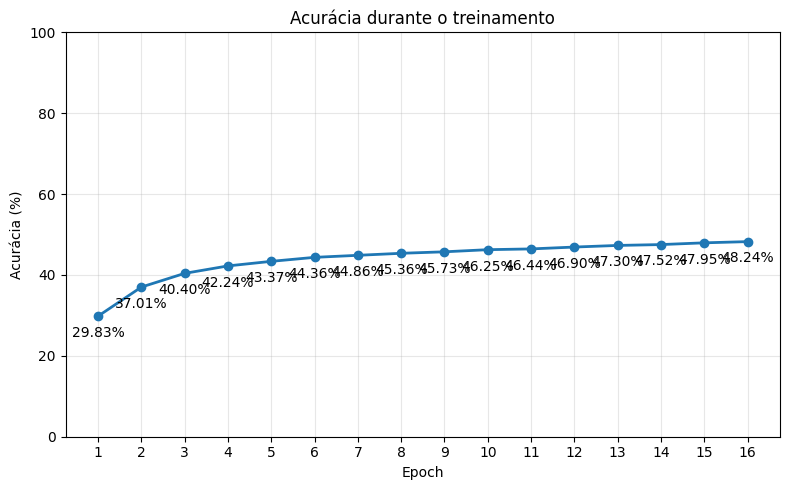

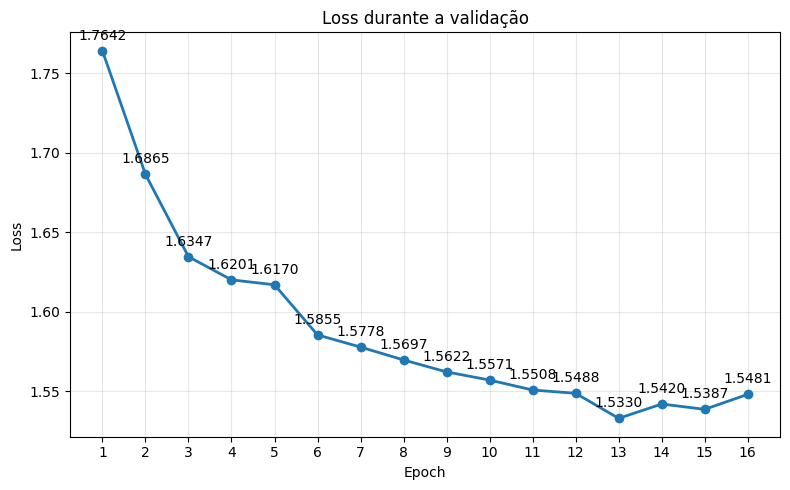

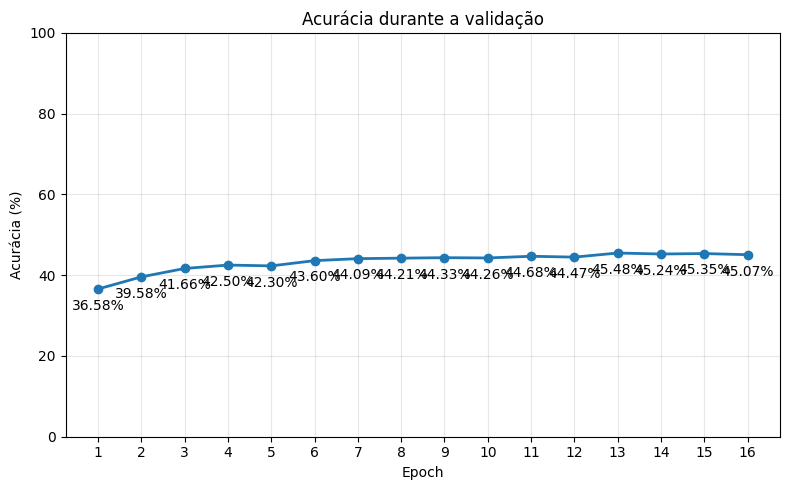

In [ ]:
total_amostras_treino = len(train_data.dataset)
total_amostras_validacao = len(validation_data.dataset)

AcuraciaEmCadaEpoch_NN = []
AcuraciaValidacaoEmCadaEpoch_NN = []

for acertos in AcertosEmCadaEpoch_NN:
    acuracia = (acertos.item() / total_amostras_treino) * 100
    AcuraciaEmCadaEpoch_NN.append(acuracia)

for acertos in AcertosEmCadaEpoch_Validacao_NN:
    acuracia = (acertos.item() / total_amostras_validacao) * 100
    AcuraciaValidacaoEmCadaEpoch_NN.append(acuracia)

epochs_lista = range(1, epocas_NN + 1)


## Treino
plt.figure(figsize=(8, 5))

plt.plot(epochs_lista, LossMediaEmCadaEpoch_NN, marker='o', linewidth=2)

for i in range(len(LossMediaEmCadaEpoch_NN)):
    plt.annotate(f'{LossMediaEmCadaEpoch_NN[i]:.4f}', (epochs_lista[i], LossMediaEmCadaEpoch_NN[i]), xytext=(0, 8), textcoords='offset points', ha='center')

plt.title('Loss durante o treinamento')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.xticks(epochs_lista)
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


plt.figure(figsize=(8, 5))

plt.plot(epochs_lista, AcuraciaEmCadaEpoch_NN, marker='o', linewidth=2)

for i in range(len(AcuraciaEmCadaEpoch_NN)):
    plt.annotate(f'{AcuraciaEmCadaEpoch_NN[i]:.2f}%', (epochs_lista[i], AcuraciaEmCadaEpoch_NN[i]), xytext=(0, -15), textcoords='offset points', ha='center')

plt.title('Acurácia durante o treinamento')
plt.xlabel('Epoch')
plt.ylabel('Acurácia (%)')
plt.xticks(epochs_lista)
plt.ylim(0, 100)
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

##

## Validacao

plt.figure(figsize=(8, 5))

plt.plot(epochs_lista, LossMediaEmCadaEpoch_Validacao_NN, marker='o', linewidth=2)

for i in range(len(LossMediaEmCadaEpoch_Validacao_NN)):
    plt.annotate(f'{LossMediaEmCadaEpoch_Validacao_NN[i]:.4f}', (epochs_lista[i], LossMediaEmCadaEpoch_Validacao_NN[i]), xytext=(0, 8), textcoords='offset points', ha='center')

plt.title('Loss durante a validação')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.xticks(epochs_lista)
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


plt.figure(figsize=(8, 5))

plt.plot(epochs_lista, AcuraciaValidacaoEmCadaEpoch_NN, marker='o', linewidth=2)

for i in range(len(AcuraciaValidacaoEmCadaEpoch_NN)):
    plt.annotate(f'{AcuraciaValidacaoEmCadaEpoch_NN[i]:.2f}%', (epochs_lista[i], AcuraciaValidacaoEmCadaEpoch_NN[i]), xytext=(0, -15), textcoords='offset points', ha='center')

plt.title('Acurácia durante a validação')
plt.xlabel('Epoch')
plt.ylabel('Acurácia (%)')
plt.xticks(epochs_lista)
plt.ylim(0, 100)
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

##


## Treinando e testando a CNN usando otimizador Adam e diminuindo o learning rate:

In [ ]:
model_cnn_cifar10 = CNN(10,3, 32)

criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model_cnn_cifar10.parameters(), lr=0.0005)

patience = 3
delta = 0.01
melhor_loss_validacao = float('inf')
epochs_sem_melhora = 0

epochs = 50
AcertosEmCadaEpoch_CNN = []
LossMediaEmCadaEpoch_CNN = []
AcertosEmCadaEpoch_Validacao_CNN = []
LossMediaEmCadaEpoch_Validacao_CNN = []
start_time_CNN = time.time()

for i in range(epochs):
  AcertosNaEpoch = 0
  SomaLossNaEpoch = 0


  # Train
  for b,(x_train, y_train) in enumerate(train_data):
    y_pred = model_cnn_cifar10(x_train)
    loss = criterion(y_pred, y_train)

    predicted = torch.argmax(y_pred, dim=1)
    acertosNoBatch = (predicted == y_train).sum()
    AcertosNaEpoch += acertosNoBatch
    SomaLossNaEpoch += loss.item()

    optimizer.zero_grad()
    loss.backward()
    optimizer.step()


    if b%600 == 0:
      print(f'Epoch: {i+1}  Batch: {b}  Loss: {loss.item()}')

  AcertosEmCadaEpoch_CNN.append(AcertosNaEpoch)
  LossMediaEmCadaEpoch_CNN.append(SomaLossNaEpoch/len(train_data))


  # Validation
  AcertosNaValidacao = 0
  SomaLossNaValidacao = 0

  with torch.no_grad():
      for x_validation, y_validation in validation_data:
          y_pred = model_cnn_cifar10(x_validation)
          loss = criterion(y_pred, y_validation)

          predicted = torch.argmax(y_pred, dim=1)

          acertosNoBatch = (predicted == y_validation).sum()
          AcertosNaValidacao += acertosNoBatch
          SomaLossNaValidacao += loss.item()

  LossValidacaoAtual = SomaLossNaValidacao / len(validation_data)
  AcertosEmCadaEpoch_Validacao_CNN.append(AcertosNaValidacao)
  LossMediaEmCadaEpoch_Validacao_CNN.append(LossValidacaoAtual)

  if melhor_loss_validacao - LossValidacaoAtual > delta:
    melhor_loss_validacao = LossValidacaoAtual
    epochs_sem_melhora = 0
  else:
    epochs_sem_melhora += 1

  if epochs_sem_melhora >= patience:
    print(f'Early Stopping na epoch {i+1}')
    break


current_time_CNN = time.time()
total_time_CNN = current_time_CNN - start_time_CNN
epocas_CNN = len(AcertosEmCadaEpoch_CNN)

# Test
AcertosNoTest = 0
SomaLossNoTeste = 0
with torch.no_grad():
  for b,(x_test, y_test) in enumerate(test_data):
    y_pred = model_cnn_cifar10(x_test)
    predicted = torch.argmax(y_pred, dim=1)
    loss = criterion(y_pred, y_test)
    SomaLossNoTeste += loss.item()
    AcertosNoBacth = (predicted == y_test).sum()
    AcertosNoTest += AcertosNoBacth

LossMediaNoTeste = SomaLossNoTeste/len(test_data)

Epoch: 1  Batch: 0  Loss: 2.28831148147583
Epoch: 1  Batch: 600  Loss: 1.6077144145965576
Epoch: 1  Batch: 1200  Loss: 2.1148431301116943
Epoch: 1  Batch: 1800  Loss: 1.9507923126220703
Epoch: 1  Batch: 2400  Loss: 1.662939429283142
Epoch: 1  Batch: 3000  Loss: 1.3279588222503662
Epoch: 1  Batch: 3600  Loss: 1.4935357570648193
Epoch: 2  Batch: 0  Loss: 1.372635841369629
Epoch: 2  Batch: 600  Loss: 1.2290667295455933
Epoch: 2  Batch: 1200  Loss: 1.6883900165557861
Epoch: 2  Batch: 1800  Loss: 1.5735652446746826
Epoch: 2  Batch: 2400  Loss: 0.9529755711555481
Epoch: 2  Batch: 3000  Loss: 0.9780566096305847
Epoch: 2  Batch: 3600  Loss: 1.4477907419204712
Epoch: 3  Batch: 0  Loss: 1.2382210493087769
Epoch: 3  Batch: 600  Loss: 1.2760182619094849
Epoch: 3  Batch: 1200  Loss: 1.4226067066192627
Epoch: 3  Batch: 1800  Loss: 1.5371845960617065
Epoch: 3  Batch: 2400  Loss: 0.5437792539596558
Epoch: 3  Batch: 3000  Loss: 0.7464190721511841
Epoch: 3  Batch: 3600  Loss: 1.3064502477645874
Epoch: 4

In [ ]:
print(f'Loss media no teste: {LossMediaNoTeste}')
print(f'Acertos no test: {AcertosNoTest}')
AcuraciaNoTeste = (AcertosNoTest.item() / len(test_data.dataset)) * 100
print(f'Acurácia no teste: {AcuraciaNoTeste:.2f}%')
print(f'Tempo ate a convergencia: {total_time_CNN} segundos')
print(f'Numero de epocas ate a convergencia: {epocas_CNN}')

Loss media no teste: 1.0070025951322168
Acertos no test: 6711
Acurácia no teste: 67.11%
Tempo ate a convergencia: 663.0507678985596 segundos
Numero de epocas ate a convergencia: 12


### Visualizando os resultados:

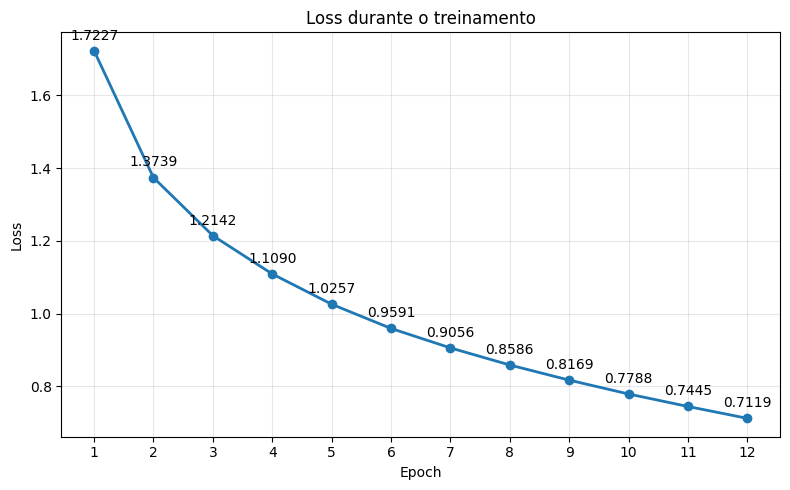

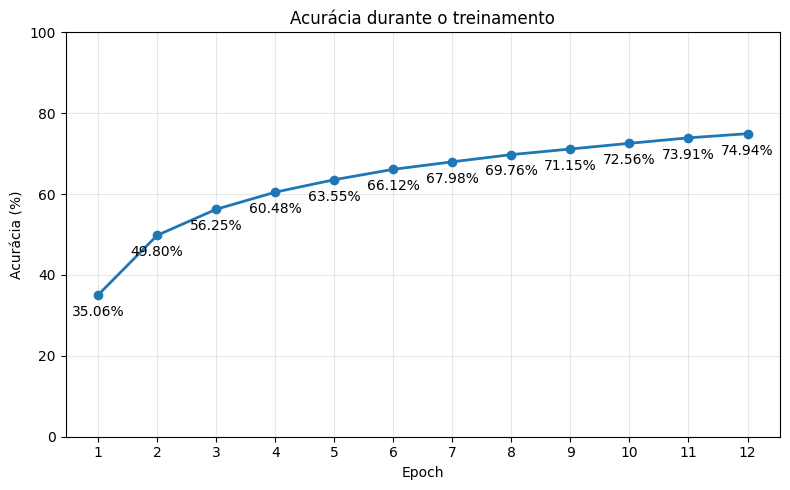

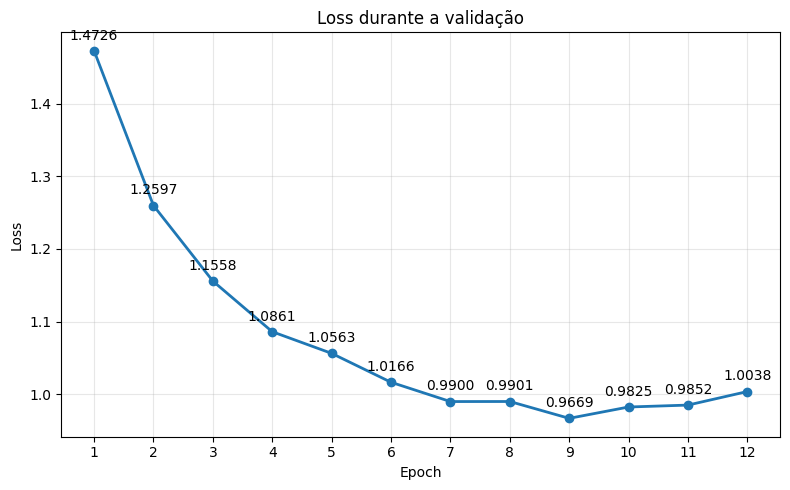

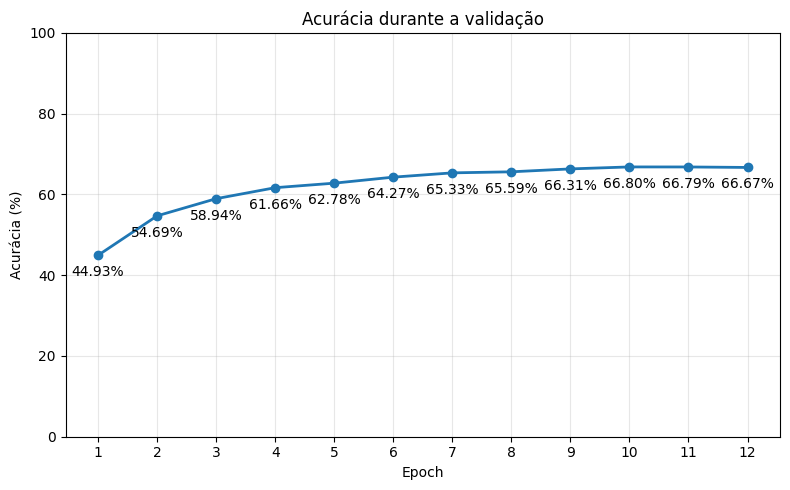

In [ ]:
total_amostras_treino = len(train_data.dataset)
total_amostras_validacao = len(validation_data.dataset)

AcuraciaEmCadaEpoch_CNN = []
AcuraciaValidacaoEmCadaEpoch_CNN = []

for acertos in AcertosEmCadaEpoch_CNN:
    acuracia = (acertos.item() / total_amostras_treino) * 100
    AcuraciaEmCadaEpoch_CNN.append(acuracia)

for acertos in AcertosEmCadaEpoch_Validacao_CNN:
    acuracia = (acertos.item() / total_amostras_validacao) * 100
    AcuraciaValidacaoEmCadaEpoch_CNN.append(acuracia)

epochs_lista = range(1, epocas_CNN + 1)

plt.figure(figsize=(8, 5))

plt.plot(epochs_lista, LossMediaEmCadaEpoch_CNN, marker='o', linewidth=2)

for i in range(len(LossMediaEmCadaEpoch_CNN)):
    plt.annotate(f'{LossMediaEmCadaEpoch_CNN[i]:.4f}', (epochs_lista[i], LossMediaEmCadaEpoch_CNN[i]), xytext=(0, 8), textcoords='offset points', ha='center')

plt.title('Loss durante o treinamento')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.xticks(epochs_lista)
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


plt.figure(figsize=(8, 5))

plt.plot(epochs_lista, AcuraciaEmCadaEpoch_CNN, marker='o', linewidth=2)

for i in range(len(AcuraciaEmCadaEpoch_CNN)):
    plt.annotate(f'{AcuraciaEmCadaEpoch_CNN[i]:.2f}%', (epochs_lista[i], AcuraciaEmCadaEpoch_CNN[i]), xytext=(0, -15), textcoords='offset points', ha='center')

plt.title('Acurácia durante o treinamento')
plt.xlabel('Epoch')
plt.ylabel('Acurácia (%)')
plt.xticks(epochs_lista)
plt.ylim(0, 100)
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()



## Validacao

plt.figure(figsize=(8, 5))

plt.plot(epochs_lista, LossMediaEmCadaEpoch_Validacao_CNN, marker='o', linewidth=2)

for i in range(len(LossMediaEmCadaEpoch_Validacao_CNN)):
    plt.annotate(f'{LossMediaEmCadaEpoch_Validacao_CNN[i]:.4f}', (epochs_lista[i], LossMediaEmCadaEpoch_Validacao_CNN[i]), xytext=(0, 8), textcoords='offset points', ha='center')

plt.title('Loss durante a validação')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.xticks(epochs_lista)
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


plt.figure(figsize=(8, 5))

plt.plot(epochs_lista, AcuraciaValidacaoEmCadaEpoch_CNN, marker='o', linewidth=2)

for i in range(len(AcuraciaValidacaoEmCadaEpoch_CNN)):
    plt.annotate(f'{AcuraciaValidacaoEmCadaEpoch_CNN[i]:.2f}%', (epochs_lista[i], AcuraciaValidacaoEmCadaEpoch_CNN[i]), xytext=(0, -15), textcoords='offset points', ha='center')

plt.title('Acurácia durante a validação')
plt.xlabel('Epoch')
plt.ylabel('Acurácia (%)')
plt.xticks(epochs_lista)
plt.ylim(0, 100)
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

##

